# Taller 2 — Screener financiero de la industria de cosmética y maquillaje
**Finanzas Computacionales · Magíster en Business Analytics (UAI)**  
**Autor:** Doménica Mercado Fernández · **Profesor:** Gabriel Valenzuela · **Fecha:** 22 de octubre 2026

## Resumen ejecutivo


**L'Oréal es la empresa más sólida del grupo.** En un período en que el sector se deterioró (tres
de cinco empresas con pérdidas en 2025), mantuvo un margen operacional cercano a 20%, el ROE más
alto (17,5%) y ninguna señal de alerta. e.l.f. Beauty empata en el screening como alternativa de
crecimiento, pero su solidez financiera se debilita en 2026. Coty presenta riesgo de insolvencia
(Altman Z'' en zona de quiebra) y se recomienda evitarla; Estée Lauder y Shiseido quedan en
observación.

## Contexto

La industria de la belleza es uno de los segmentos más resilientes del consumo masivo, pero en los
últimos años las grandes compañías han seguido caminos muy distintos: algunas mantienen márgenes y
crecimiento estables, otras enfrentan pérdidas, reestructuraciones y ventas de negocios, y aparecen
competidores jóvenes que crecen a tasas muy altas.

Este trabajo construye un **screener** para comparar a cinco de las principales empresas de
cosmética y maquillaje que cotizan en bolsa, identificando sus **fortalezas, debilidades y señales
de alerta** sobre la calidad de sus utilidades y su solvencia.

| Empresa | Ticker | Bolsa | Marcas de maquillaje | Norma contable |
|---|---|---|---|---|
| **L'Oréal** (foco) | `OR.PA` | Euronext París | Maybelline, NYX, Lancôme, Urban Decay | IFRS |
| Estée Lauder | `EL` | NYSE | MAC, Clinique, Too Faced, Bobbi Brown | US GAAP |
| Coty | `COTY` | NYSE | CoverGirl, Max Factor, Rimmel | US GAAP |
| Shiseido | `4911.T` | Tokio | Shiseido, NARS, Clé de Peau | IFRS |
| e.l.f. Beauty | `ELF` | NYSE | e.l.f., Rhode | US GAAP |

**¿Por qué L'Oréal como empresa foco?** Es el líder mundial del sector y la referencia natural
contra la que se mide el resto. Además, mantiene utilidades positivas en todo el período, lo que
permite aplicar la atribución logarítmica de la variación del ROE.

**¿Por qué estos pares?** Las cinco compiten en el mismo mercado (maquillaje y cuidado personal),
con marcas reconocidas a nivel global, y cubren los distintos modelos de negocio de la industria:
prestige (Estée Lauder, Shiseido), masivo (Coty), alto crecimiento (e.l.f.) y el líder diversificado
(L'Oréal). Las diferencias de tamaño, moneda, norma contable y cierre fiscal se abordan en la
sección 1.

## Estructura del trabajo

| Sección | Contenido |
|---|---|
| 1 | **Datos**: descarga desde `yfinance`, almacenamiento reproducible y control de calidad |
| 2 | **Ratios** de las cuatro familias (liquidez, rentabilidad, endeudamiento y eficiencia) |
| 3 | **DuPont por niveles**, con la atribución del cambio del ROE de L'Oréal |
| 4 | **Common-size** del estado de resultados y del balance |
| 5 | **Tendencias**: índice base 100 y CAGR |
| 6 | **Peer screening** y ranking, con sensibilidad a los pesos |
| 7 | **Calidad de las utilidades**: accruals |
| 8 | **Beneish M-Score** |
| 9 | **Altman Z y Z''** |
| 10 | **Tablero de alertas** |
| 11 | **Dashboard** interactivo en Streamlit |
| 12 | **Ranking final y recomendación** |

> **Fuente de datos:** estados financieros anuales de `yfinance` (Yahoo Finance). Los datos crudos
> se guardan localmente en formato Parquet con su fecha de descarga para asegurar la reproducibilidad.

## Configuración del entorno

Librerías, paleta de colores y formato de los gráficos usados en todo el notebook.

In [3]:
import os, json, time, warnings, datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.colors import LinearSegmentedColormap
import yfinance as yf

warnings.filterwarnings("ignore", category=FutureWarning)

NAVY, BLUE, ACCENT, GREY, LIGHT = "#1F3864", "#2E5496", "#C55A11", "#8A8F98", "#DEE7F2"
GREEN, RED, AMBER = "#2E7D57", "#B23A3A", "#C9A227"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlecolor": NAVY, "axes.titlelocation": "left", "font.size": 10})
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")


def separar(valores, gap):
    # Posiciones verticales para etiquetas al final de las líneas, sin superponerse
    orden = sorted(valores.items(), key=lambda kv: kv[1])
    pos, ultimo = {}, -np.inf
    for k, v in orden:
        ultimo = max(v, ultimo + gap)
        pos[k] = ultimo
    return pos


print("Entorno listo. yfinance", yf.__version__)

Entorno listo. yfinance 0.2.66


## 1. Datos: carga del panel de estados financieros

El análisis necesita un **panel en formato largo**: una fila por empresa-año y una columna por
partida contable (montos en miles de millones de la moneda de cada empresa). Los datos crudos se
guardan en Parquet con metadatos (fuente y fecha de descarga), de modo que el análisis sea
reproducible aunque `yfinance` cambie.

> **Nota de reproducibilidad.** Las interpretaciones de este notebook se redactaron con los datos
> descargados de yfinance el 22 de octubre de 2026. Si se ejecuta en otra fecha, los gráficos y
> tablas se recalculan automáticamente, pero las cifras citadas en el texto podrían diferir
> levemente por revisiones de la fuente.

### 1.1 Parámetros y mapa de partidas

In [4]:
EMPRESAS = {
    "OR.PA":  "L'Oréal",
    "EL":     "Estée Lauder",
    "COTY":   "Coty",
    "4911.T": "Shiseido",
    "ELF":    "e.l.f. Beauty",
}
FOCO    = "L'Oréal"
RAW_DIR = "datos/crudos"


MAPA = {
    "revenue":            ("is", ["Total Revenue", "Operating Revenue"]),
    "cogs":               ("is", ["Cost Of Revenue", "Reconciled Cost Of Revenue"]),
    "gross_profit_rep":   ("is", ["Gross Profit"]),
    "sga":                ("is", ["Selling General And Administration"]),
    "depreciation":       ("cf", ["Depreciation And Amortization", "Depreciation Amortization Depletion"]),
    "ebit":               ("is", ["EBIT", "Operating Income"]),
    "interest_expense":   ("is", ["Interest Expense", "Interest Expense Non Operating"]),
    "pretax_income":      ("is", ["Pretax Income"]),
    "net_income":         ("is", ["Net Income", "Net Income Common Stockholders"]),
    "cfo":                ("cf", ["Operating Cash Flow", "Cash Flow From Continuing Operating Activities"]),
    "total_assets":       ("bs", ["Total Assets"]),
    "current_assets":     ("bs", ["Current Assets"]),
    "cash":               ("bs", ["Cash And Cash Equivalents", "Cash Cash Equivalents And Short Term Investments"]),
    "receivables":        ("bs", ["Accounts Receivable", "Receivables", "Gross Accounts Receivable"]),
    "inventory":          ("bs", ["Inventory"]),
    "ppe":                ("bs", ["Net PPE"]),
    "total_liabilities":  ("bs", ["Total Liabilities Net Minority Interest"]),
    "current_liabilities":("bs", ["Current Liabilities"]),
    "accounts_payable":   ("bs", ["Accounts Payable", "Payables"]),
    "long_term_debt":     ("bs", ["Long Term Debt", "Long Term Debt And Capital Lease Obligation"]),
    "equity":             ("bs", ["Stockholders Equity", "Common Stock Equity"]),
    "retained_earnings":  ("bs", ["Retained Earnings"]),
    "shares":             ("bs", ["Ordinary Shares Number", "Share Issued"]),
}

### 1.2 Descarga con caché (capa cruda)

In [5]:
def _a_numerico(df):
    return df.apply(pd.to_numeric, errors="coerce")


def descargar_crudos(tk, forzar=False):
    """Descarga los 3 estados anuales + precios mensuales de un ticker.
    Los guarda en Parquet con metadatos; si ya existen, los lee del disco (caché)."""
    carpeta = os.path.join(RAW_DIR, tk.replace(".", "_"))
    ruta_meta = os.path.join(carpeta, "metadatos.json")

    if os.path.exists(ruta_meta) and not forzar:
        est = {}
        for k in ("is", "bs", "cf"):
            df = pd.read_parquet(os.path.join(carpeta, f"{k}.parquet"))
            df.columns = pd.to_datetime(df.columns)
            est[k] = df
        precios = pd.read_parquet(os.path.join(carpeta, "precios.parquet"))["Close"]
        with open(ruta_meta) as f:
            meta = json.load(f)
        return est, precios, meta

    os.makedirs(carpeta, exist_ok=True)
    t = yf.Ticker(tk)
    est = {"is": t.financials, "bs": t.balance_sheet, "cf": t.cashflow}
    for k, df in est.items():
        if df is None or df.empty:
            raise RuntimeError(f"{tk}: el estado '{k}' viene vacío")
        df = _a_numerico(df)
        df.columns = pd.to_datetime(df.columns)
        est[k] = df
        df.rename(columns=lambda c: c.strftime("%Y-%m-%d")).to_parquet(os.path.join(carpeta, f"{k}.parquet"))

    # Precio de cierre SIN ajuste por dividendos: es el que corresponde para la capitalización bursátil
    hist = t.history(period="10y", interval="1mo", auto_adjust=False)
    precios = hist["Close"]
    precios.index = precios.index.tz_localize(None)
    precios.to_frame().to_parquet(os.path.join(carpeta, "precios.parquet"))

    try:
        moneda = t.fast_info["currency"]
    except Exception:
        moneda = None
    meta = {"ticker": tk, "nombre": EMPRESAS[tk], "moneda": moneda,
            "fuente": f"yfinance {yf.__version__}",
            "descargado": dt.datetime.now().isoformat(timespec="seconds"),
            "precio": "Close mensual, auto_adjust=False (sin ajuste por dividendos)"}
    with open(ruta_meta, "w") as f:
        json.dump(meta, f, indent=2, ensure_ascii=False)
    return est, precios, meta


crudos, errores = {}, {}
for tk in EMPRESAS:
    try:
        crudos[tk] = descargar_crudos(tk)
        m = crudos[tk][2]
        print(f"OK  {tk:7s} {m['nombre']:15s} moneda={m['moneda']}  descargado={m['descargado']}")
    except Exception as e:
        errores[tk] = f"{type(e).__name__}: {e}"
        print(f"ERR {tk:7s} {errores[tk]}")
    time.sleep(1)   # evita bloqueos por exceso de consultas

OK  OR.PA   L'Oréal         moneda=EUR  descargado=2026-10-22T21:22:00
OK  EL      Estée Lauder    moneda=USD  descargado=2026-10-22T21:22:02
OK  COTY    Coty            moneda=USD  descargado=2026-10-22T21:22:04
OK  4911.T  Shiseido        moneda=JPY  descargado=2026-10-22T21:22:06
OK  ELF     e.l.f. Beauty   moneda=USD  descargado=2026-10-22T21:22:08


### 1.3 Construcción del panel (capa limpia)

In [6]:
def valor(est, fuente, nombres, fecha):
    # Primer nombre que exista Y tenga dato en esa fecha
    s = est[fuente]
    if fecha not in s.columns:
        return np.nan
    for n in nombres:
        if n in s.index and pd.notna(s.at[n, fecha]):
            return float(s.at[n, fecha])
    return np.nan


def armar_panel(crudos):
    filas = []
    for tk, (est, precios, meta) in crudos.items():
        for fecha in est["is"].columns:
            fila = {"empresa": meta["nombre"], "ticker": tk, "anio": fecha.year,
                    "cierre_fiscal": fecha.date(), "moneda": meta["moneda"]}
            for col, (fuente, nombres) in MAPA.items():
                fila[col] = valor(est, fuente, nombres, fecha) / 1e9      # miles de millones
            # SG&A: algunas empresas IFRS lo reportan separado (ventas + administración)
            if np.isnan(fila["sga"]):
                partes = [valor(est, "is", [n], fecha)
                          for n in ("Selling And Marketing Expense", "General And Administrative Expense")]
                if not np.all(np.isnan(partes)):
                    fila["sga"] = np.nansum(partes) / 1e9
            # Capitalización al cierre fiscal = precio de cierre del mes × acciones
            p = precios[precios.index <= pd.Timestamp(fecha)]
            fila["market_cap"] = p.iloc[-1] * fila["shares"] if len(p) else np.nan
            filas.append(fila)

    df = pd.DataFrame(filas)
    # Costo de ventas: si falta, se reconstruye desde la utilidad bruta reportada
    df["cogs"] = df["cogs"].fillna(df.revenue - df.gross_profit_rep)
    df["gross_profit"] = df.revenue - df.cogs
    df["interest_expense"] = df.interest_expense.abs()
    df["depreciation"] = df.depreciation.abs()
    df = df.drop(columns="gross_profit_rep")

    # yfinance suele traer el año más antiguo casi vacío: se descarta, pero se informa
    clave = ["revenue", "net_income", "cfo", "total_assets", "equity", "current_liabilities"]
    incompletas = df[df[clave].isna().any(axis=1)]
    if len(incompletas):
        print("Filas descartadas por falta de partidas clave:")
        print(incompletas[["empresa", "anio"]].to_string(index=False))
    return df.dropna(subset=clave).sort_values(["empresa", "anio"]).reset_index(drop=True)


panel = armar_panel(crudos)
EMP = sorted(panel.empresa.unique())

# Último año en que TODAS las empresas tienen estados (cierres fiscales distintos)
ANIO = int(panel.groupby("empresa").anio.max().min())
print(f"\n{panel.empresa.nunique()} empresas | años {panel.anio.min()}–{panel.anio.max()} | "
      f"año de comparación común: {ANIO} | foco: {FOCO}")
panel.head()

Filas descartadas por falta de partidas clave:
      empresa  anio
      L'Oréal  2021
         Coty  2022
     Shiseido  2021
e.l.f. Beauty  2022

5 empresas | años 2022–2026 | año de comparación común: 2025 | foco: L'Oréal


,empresa,ticker,anio,cierre_fiscal,moneda,revenue,cogs,sga,depreciation,ebit,...,ppe,total_liabilities,current_liabilities,accounts_payable,long_term_debt,equity,retained_earnings,shares,market_cap,gross_profit
0,Coty,COTY,2023,2023-06-30,USD,5.554,2.007,2.818,0.427,0.966,...,1.000,8.428,2.737,1.445,4.178,3.954,-4.988,0.853,10.481,3.547
1,Coty,COTY,2024,2024-06-30,USD,6.118,2.179,3.162,0.421,0.456,...,0.974,7.835,2.602,1.998,3.842,3.970,-4.899,0.868,8.695,3.939
2,Coty,COTY,2025,2025-06-30,USD,5.893,2.072,3.103,0.420,-0.118,...,0.975,7.952,2.538,1.890,3.955,3.685,-5.266,0.872,4.056,3.821
3,Coty,COTY,2026,2026-06-30,USD,5.807,2.155,3.108,0.482,-0.426,...,0.877,6.821,2.541,1.875,3.033,3.132,-5.878,0.880,1.901,3.652
4,Estée Lauder,EL,2023,2023-06-30,USD,15.910,4.564,9.575,0.744,1.652,...,4.976,16.998,6.240,1.670,7.117,5.585,13.991,0.358,70.229,11.346


### 1.4 Control de calidad del panel

Antes de calcular ratios se verifica que el panel sea coherente: años y cierre fiscal de cada
empresa, la identidad del balance (activos = pasivos + patrimonio) y la cobertura de cada partida.

In [7]:
# 1) Años, cierre fiscal y moneda por empresa
resumen = panel.groupby("empresa").agg(moneda=("moneda", "first"),
                                        desde=("anio", "min"), hasta=("anio", "max"),
                                        n_anios=("anio", "count"),
                                        mes_cierre=("cierre_fiscal", lambda s: s.iloc[-1].strftime("%b")))
display(resumen)

# 2) Identidad del balance: activos = pasivos + patrimonio (el residuo es el interés minoritario)
descuadre = (panel.total_assets - panel.total_liabilities - panel.equity) / panel.total_assets
print("Descuadre máximo del balance (% de activos):", f"{descuadre.abs().max():.2%}")

# 3) Cobertura: % de años con dato, por partida y empresa
cols = [c for c in MAPA if c not in ("gross_profit_rep",)] + ["market_cap"]
cobertura = panel.groupby("empresa")[cols].apply(lambda d: d.notna().mean()).T
display(cobertura.style.format("{:.0%}").background_gradient(cmap="RdYlGn", vmin=0, vmax=1))

# 4) Guardar la capa limpia (Parquet para el análisis, CSV para el dashboard)
os.makedirs("datos", exist_ok=True)
panel.to_parquet("datos/panel_limpio.parquet", index=False)
panel.to_csv("panel_para_dashboard.csv", index=False)
print("Panel guardado en datos/panel_limpio.parquet y panel_para_dashboard.csv")

,moneda,desde,hasta,n_anios,mes_cierre
empresa,,,,,
Coty,USD,2023,2026,4,Jun
Estée Lauder,USD,2023,2026,4,Jun
L'Oréal,EUR,2022,2025,4,Dec
Shiseido,JPY,2022,2025,4,Dec
e.l.f. Beauty,USD,2023,2026,4,Mar


Descuadre máximo del balance (% de activos): 3.55%


empresa,Coty,Estée Lauder,L'Oréal,Shiseido,e.l.f. Beauty
revenue,100%,100%,100%,100%,100%
cogs,100%,100%,100%,100%,100%
sga,100%,100%,100%,100%,100%
depreciation,100%,100%,100%,100%,100%
ebit,100%,100%,100%,100%,100%
interest_expense,100%,100%,100%,100%,100%
pretax_income,100%,100%,100%,100%,100%
net_income,100%,100%,100%,100%,100%
cfo,100%,100%,100%,100%,100%
total_assets,100%,100%,100%,100%,100%


Panel guardado en datos/panel_limpio.parquet y panel_para_dashboard.csv


**Lectura del control de calidad.** Las cinco empresas cuentan con cuatro ejercicios anuales
(sobre el mínimo de tres exigido). Los cierres fiscales difieren (diciembre para L'Oréal y
Shiseido, junio para Estée Lauder y Coty, marzo para e.l.f.), por lo que `anio` corresponde al
año de cierre de cada ejercicio y el corte transversal se realiza en 2025, último año disponible
para todo el grupo. El descuadre máximo del balance es de 3,55% de los activos y corresponde al
interés minoritario, que yfinance excluye tanto del pasivo como del patrimonio de los
controladores; no es un error de datos. La cobertura de las partidas necesarias es completa, por
lo que todos los indicadores pueden calcularse para las cinco empresas.

### 1.5 Desglose del descuadre del balance

In [8]:
#Desglose del Descuadre máximo del balance (% de activos): 3.55%
panel.assign(descuadre=descuadre).pivot(index="anio", columns="empresa", values="descuadre").style.format("{:.2%}")

empresa,Coty,Estée Lauder,L'Oréal,Shiseido,e.l.f. Beauty
anio,,,,,
2022,nan%,nan%,0.02%,1.64%,nan%
2023,2.21%,3.55%,0.01%,1.72%,0.00%
2024,2.30%,0.00%,0.01%,1.66%,-0.00%
2025,2.27%,-0.00%,0.08%,1.62%,0.00%
2026,2.42%,0.00%,nan%,nan%,0.00%


**¿Qué hace este código?** Calcula, para cada empresa y año, cuánto falta para que se cumpla la
identidad contable *Activos = Pasivos + Patrimonio*, expresado como % de los activos, y lo ordena
en una tabla con los años en las filas y las empresas en las columnas.

**Lectura.** Las diferencias son pequeñas (máximo 3,55%) y no corresponden a errores de datos:
yfinance excluye del pasivo y del patrimonio de los controladores el **interés minoritario**, es
decir, la parte de las filiales que pertenece a otros socios. L'Oréal y e.l.f. cuadran casi
exactamente porque controlan prácticamente el 100% de sus filiales. Shiseido (~1,7%) y Coty (~2,3%)
muestran una diferencia pequeña y estable en el tiempo, propia de participaciones minoritarias. En
Estée Lauder la diferencia aparece solo en 2023 (3,55%) y desaparece desde 2024, lo que es coherente
con la adquisición de una participación minoritaria. Como el patrimonio usado en los ratios es el
de los controladores, este residuo **no afecta el ROE** ni el resto de los indicadores. Se concluye que
el panel es contablemente consistente.

## 2. Ratios de las cuatro familias

Las cuatro familias de ratios (liquidez, rentabilidad, endeudamiento y eficiencia) se calculan con
una sola función sobre el panel completo. Como cada fila es una empresa-año, el resultado sirve
tanto para comparar empresas en un mismo año (corte transversal) como para seguir su evolución
(tendencias). Un ratio aislado no dice nada: se interpreta frente a la **mediana del grupo** y
frente a la **historia** de la propia empresa.

### 2.1 Cálculo de ratios y tabla del año común

In [9]:
def ratios(df):
    r = df[["empresa", "anio"]].copy()
    # Liquidez
    r["Razón corriente"]        = df.current_assets / df.current_liabilities
    r["Prueba ácida"]           = (df.current_assets - df.inventory) / df.current_liabilities
    # Rentabilidad
    r["Margen bruto"]           = df.gross_profit / df.revenue
    r["Margen operacional"]     = df.ebit / df.revenue
    r["Margen neto"]            = df.net_income / df.revenue
    r["ROA"]                    = df.net_income / df.total_assets
    r["ROE"]                    = df.net_income / df.equity
    # Endeudamiento
    r["Deuda/Patrimonio"]       = df.total_liabilities / df.equity
    r["Cobertura de intereses"] = df.ebit / df.interest_expense
    # Eficiencia
    r["Rotación de activos"]    = df.revenue / df.total_assets
    r["DSO (días)"]             = 365 * df.receivables / df.revenue
    r["Días de inventario"]     = 365 * df.inventory / df.cogs
    return r


R = ratios(panel)
corte = R[R.anio == ANIO].set_index("empresa").drop(columns="anio")

PCT = ["Margen bruto", "Margen operacional", "Margen neto", "ROA", "ROE"]
FMT = {**{c: "{:.1%}" for c in PCT},
       "Razón corriente": "{:.2f}", "Prueba ácida": "{:.2f}", "Deuda/Patrimonio": "{:.2f}",
       "Cobertura de intereses": "{:.1f}x", "Rotación de activos": "{:.2f}",
       "DSO (días)": "{:.0f}", "Días de inventario": "{:.0f}"}

tabla2 = pd.concat([corte, corte.median().to_frame("Mediana del grupo").T])
(tabla2.style
     .format(FMT)
     .apply(lambda f: [f"font-weight: bold; color: {ACCENT}" if f.name == FOCO
                       else ("font-style: italic" if f.name == "Mediana del grupo" else "")
                       for _ in f], axis=1)
     .set_caption(f"Ratios {ANIO} (año de cierre fiscal)"))

,Razón corriente,Prueba ácida,Margen bruto,Margen operacional,Margen neto,ROA,ROE,Deuda/Patrimonio,Cobertura de intereses,Rotación de activos,DSO (días),Días de inventario
Coty,0.77,0.46,64.8%,-2.0%,-6.2%,-3.1%,-10.0%,2.16,-0.5x,0.49,33,140
Estée Lauder,1.30,0.92,74.0%,-4.8%,-7.9%,-5.7%,-29.3%,4.15,-1.9x,0.72,39,203
L'Oréal,1.44,1.15,74.3%,20.2%,13.9%,9.9%,17.5%,0.77,23.7x,0.71,46,147
Shiseido,1.37,0.94,76.6%,-2.2%,-4.2%,-3.2%,-6.8%,1.08,-3.4x,0.77,61,237
e.l.f. Beauty,3.05,2.00,71.2%,12.3%,8.5%,9.0%,14.7%,0.64,9.7x,1.05,35,181
Mediana del grupo,1.37,0.94,74.0%,-2.0%,-4.2%,-3.1%,-6.8%,1.08,-0.5x,0.72,39,181


**Lectura de los ratios 2025.** El año fue débil para el sector: tres de las cinco empresas
(Coty, Estée Lauder y Shiseido) registran pérdidas, por lo que la mediana del grupo es negativa en
rentabilidad y debe interpretarse con cautela. El grupo comparte un modelo de negocio de **margen
alto y rotación baja**: el margen bruto es similar en todas (65–77%) y la rotación de activos es
inferior a 1, reflejo de balances con alta proporción de marcas y plusvalía. Como el margen bruto
casi no difiere, las brechas de rentabilidad (margen operacional entre −4,8% y 20,2%) se originan
en los gastos operacionales y en partidas como reestructuraciones y deterioros.

**L'Oréal** lidera en todas las medidas de rentabilidad (margen operacional 20,2%, ROE 17,5%,
ROA 9,9%) con bajo endeudamiento (Deuda/Patrimonio 0,77; cobertura de intereses 23,7x): su ROE
proviene del negocio y no del apalancamiento. Su principal debilidad relativa es la cobranza
(DSO de 46 días frente a 39 de la mediana). **e.l.f.** es el otro caso sano, con la mejor liquidez
y rotación del grupo. En el extremo opuesto, **Estée Lauder** combina pérdidas con el mayor
apalancamiento (4,15), lo que amplifica su ROE negativo (−29,3%), y **Coty** presenta liquidez
insuficiente (razón corriente 0,77).

### 2.2 Gráfico frente a la mediana

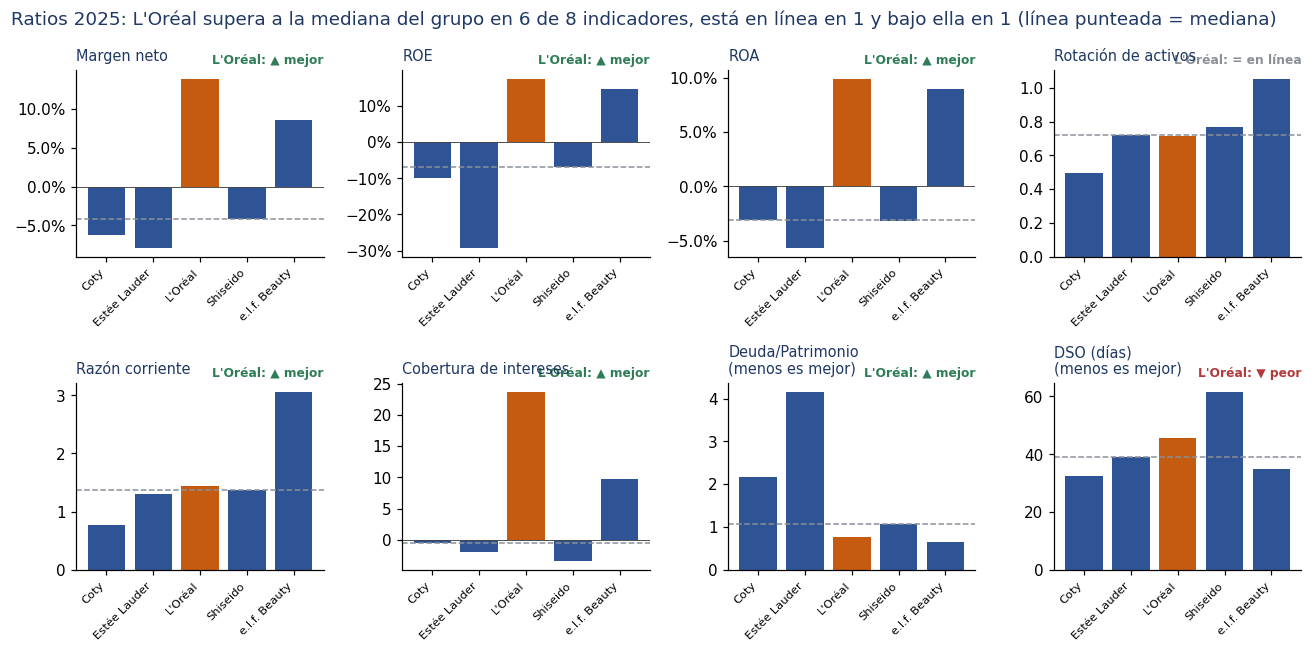

Mejor    : ['Margen neto', 'ROE', 'ROA', 'Razón corriente', 'Cobertura de intereses', 'Deuda/Patrimonio']
En línea : ['Rotación de activos']
Peor     : ['DSO (días)']


In [10]:
CLAVE = ["Margen neto", "ROE", "ROA", "Rotación de activos",
         "Razón corriente", "Cobertura de intereses", "Deuda/Patrimonio", "DSO (días)"]
MENOS_ES_MEJOR = {"Deuda/Patrimonio", "DSO (días)", "Días de inventario"}
TOL = 0.05   # diferencias menores al 5% de la mediana se consideran "en línea"


def posicion(valor, mediana, menos_es_mejor, tol=TOL):
    # Clasifica un valor frente a la mediana: "mejor", "en línea" o "peor"
    if abs(valor - mediana) <= tol * abs(mediana):
        return "en línea"
    mejor = valor < mediana if menos_es_mejor else valor > mediana
    return "mejor" if mejor else "peor"


med = corte[CLAVE].median()
pos_foco = {c: posicion(corte.loc[FOCO, c], med[c], c in MENOS_ES_MEJOR) for c in CLAVE}
n_mejor = sum(p == "mejor" for p in pos_foco.values())
n_linea = sum(p == "en línea" for p in pos_foco.values())
n_peor  = sum(p == "peor" for p in pos_foco.values())

ETIQUETA = {"mejor": ("▲ mejor", GREEN), "en línea": ("= en línea", GREY), "peor": ("▼ peor", RED)}

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, c in zip(axes.flat, CLAVE):
    v = corte[c].reindex(EMP)
    ax.bar(v.index, v, color=[ACCENT if e == FOCO else BLUE for e in v.index])
    ax.axhline(med[c], color=GREY, ls="--", lw=1)
    ax.axhline(0, color="#444", lw=0.6)
    ax.set_title(c + ("\n(menos es mejor)" if c in MENOS_ES_MEJOR else ""), fontsize=9.5)
    texto, color = ETIQUETA[pos_foco[c]]
    ax.annotate(f"{FOCO}: {texto}", xy=(1.0, 1.02), xycoords="axes fraction",
                ha="right", va="bottom", fontsize=8, fontweight="bold", color=color)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", fontsize=7.5)
    if c in PCT:
        ax.yaxis.set_major_formatter(PercentFormatter(1.0))

fig.suptitle(f"Ratios {ANIO}: {FOCO} supera a la mediana del grupo en {n_mejor} de {len(CLAVE)} "
             f"indicadores, está en línea en {n_linea} y bajo ella en {n_peor} (línea punteada = mediana)",
             x=0.01, ha="left", color=NAVY)
plt.tight_layout(); plt.show()

for categoria in ("mejor", "en línea", "peor"):
    print(f"{categoria.capitalize():9s}:", [c for c, p in pos_foco.items() if p == categoria])

**Lectura del gráfico.** L'Oréal supera a la mediana del grupo en 6 de 8 indicadores. Sus
fortalezas se concentran en **rentabilidad** (margen neto, ROE y ROA más altos del grupo, en un año
en que tres de los cinco pares registran pérdidas) y en **solidez financiera** (cobertura de
intereses de 23,7x, más del doble que el segundo, y bajo endeudamiento). De sus dos indicadores
"bajo la mediana", la rotación de activos es en la práctica un empate (0,71 frente a 0,72); la
debilidad real es la **cobranza**: con 46 días de DSO, solo Shiseido cobra más lento.

El competidor más sólido es **e.l.f. Beauty**, que supera a L'Oréal en liquidez, rotación,
endeudamiento y días de cobro. Ambas empresas sanas siguen modelos distintos: L'Oréal gana por
margen y escala; e.l.f., por eficiencia y un balance liviano.

## 3. Análisis DuPont por niveles

El análisis DuPont descompone el ROE en factores que se multiplican. Cada nivel abre el anterior:

| Nivel | Descomposición | Pregunta que responde |
|---|---|---|
| 1 | ROE = ROA × multiplicador | ¿La rentabilidad viene del negocio o del apalancamiento? |
| 2 | ROE = margen neto × rotación × multiplicador | ¿El negocio gana por margen o por volumen? |
| 3 | ROE = carga tributaria × carga de intereses × margen EBIT × rotación × multiplicador | ¿Cuánto se pierde en intereses e impuestos? |
| 4 | Motores del margen EBIT y de la rotación | ¿Qué decisiones operacionales mueven cada factor? |

### 3.1 Definiciones

| Componente | Fórmula | Cómo se lee |
|---|---|---|
| ROE | UN / Patrimonio | Utilidad por cada peso de los accionistas: lo que se busca explicar |
| ROA | UN / Activos | Rentabilidad del negocio, sin importar cómo se financia |
| Multiplicador | Activos / Patrimonio (= 1 + D/P) | Más alto: más apalancamiento; amplifica ganancias y pérdidas |
| Margen neto | UN / Ventas | Cuánto queda de cada peso vendido |
| Rotación | Ventas / Activos | Cuánto se vende por cada peso invertido |
| Carga tributaria | UN / UAI | Fracción que queda tras impuestos (= 1 − tasa efectiva) |
| Carga de intereses | UAI / EBIT | Fracción del resultado operacional que queda tras intereses |
| Margen EBIT | EBIT / Ventas | Rentabilidad de la operación, antes de financiamiento e impuestos |

### 3.2 Niveles 1 y 2: DuPont de tres factores
$$\text{ROE}=\underbrace{\frac{\text{UN}}{\text{Ventas}}}_{\text{margen}}\times
\underbrace{\frac{\text{Ventas}}{\text{Activos}}}_{\text{rotación}}\times
\underbrace{\frac{\text{Activos}}{\text{Patrimonio}}}_{\text{multiplicador}}
\qquad \text{ROA}=\text{margen}\times\text{rotación}$$

In [11]:
def dupont(df):
    d = df[["empresa", "anio"]].copy()
    d["Margen neto"]   = df.net_income / df.revenue
    d["Rotación"]      = df.revenue / df.total_assets
    d["ROA"]           = d["Margen neto"] * d["Rotación"]            # nivel 1
    d["Multiplicador"] = df.total_assets / df.equity
    d["ROE"]           = d["ROA"] * d["Multiplicador"]
    return d


D = dupont(panel)
D_ult = D[D.anio == ANIO].set_index("empresa").drop(columns="anio")

# Control: el producto de los factores debe coincidir con el ROE calculado directamente
assert np.allclose(D_ult.ROE, corte.ROE), "El DuPont no reproduce el ROE"
print("Control OK: margen × rotación × multiplicador = ROE para todas las empresas.")

tabla3 = pd.concat([D_ult, D_ult.median().to_frame("Mediana del grupo").T])
(tabla3.style
     .format({"Margen neto": "{:.1%}", "Rotación": "{:.2f}", "ROA": "{:.1%}",
              "Multiplicador": "{:.2f}", "ROE": "{:.1%}"})
     .apply(lambda f: [f"font-weight: bold; color: {ACCENT}" if f.name == FOCO
                       else ("font-style: italic" if f.name == "Mediana del grupo" else "")
                       for _ in f], axis=1)
     .set_caption(f"DuPont de tres factores, {ANIO}"))

Control OK: margen × rotación × multiplicador = ROE para todas las empresas.


,Margen neto,Rotación,ROA,Multiplicador,ROE
Coty,-6.2%,0.49,-3.1%,3.23,-10.0%
Estée Lauder,-7.9%,0.72,-5.7%,5.15,-29.3%
L'Oréal,13.9%,0.71,9.9%,1.77,17.5%
Shiseido,-4.2%,0.77,-3.2%,2.11,-6.8%
e.l.f. Beauty,8.5%,1.05,9.0%,1.64,14.7%
Mediana del grupo,-4.2%,0.72,-3.1%,2.11,-6.8%


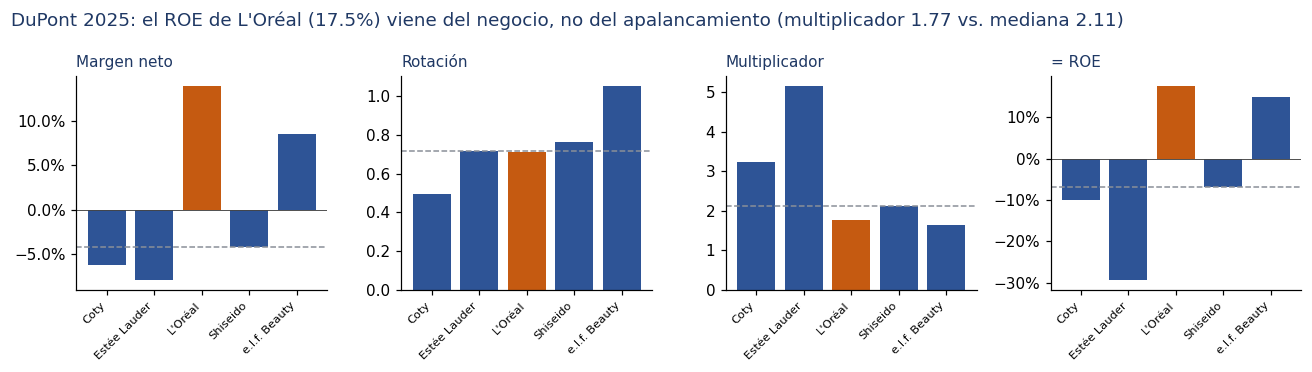

In [12]:
F3 = ["Margen neto", "Rotación", "Multiplicador", "ROE"]
med3 = D_ult[F3].median()

fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, c in zip(axes, F3):
    v = D_ult[c].reindex(EMP)
    ax.bar(v.index, v, color=[ACCENT if e == FOCO else BLUE for e in v.index])
    ax.axhline(med3[c], color=GREY, ls="--", lw=1)
    ax.axhline(0, color="#444", lw=0.6)
    ax.set_title(("= " if c == "ROE" else "") + c, fontsize=10)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", fontsize=7.5)
    if c in ("Margen neto", "ROE"):
        ax.yaxis.set_major_formatter(PercentFormatter(1.0))

# Título que comunica: ¿el ROE del foco viene del negocio o del apalancamiento?
f = D_ult.loc[FOCO]
origen = ("del apalancamiento" if f.Multiplicador > med3.Multiplicador
          else "del negocio, no del apalancamiento")
fig.suptitle(f"DuPont {ANIO}: el ROE de {FOCO} ({f.ROE:.1%}) viene {origen} "
             f"(multiplicador {f.Multiplicador:.2f} vs. mediana {med3.Multiplicador:.2f})",
             x=0.01, ha="left", color=NAVY)
plt.tight_layout(); plt.show()

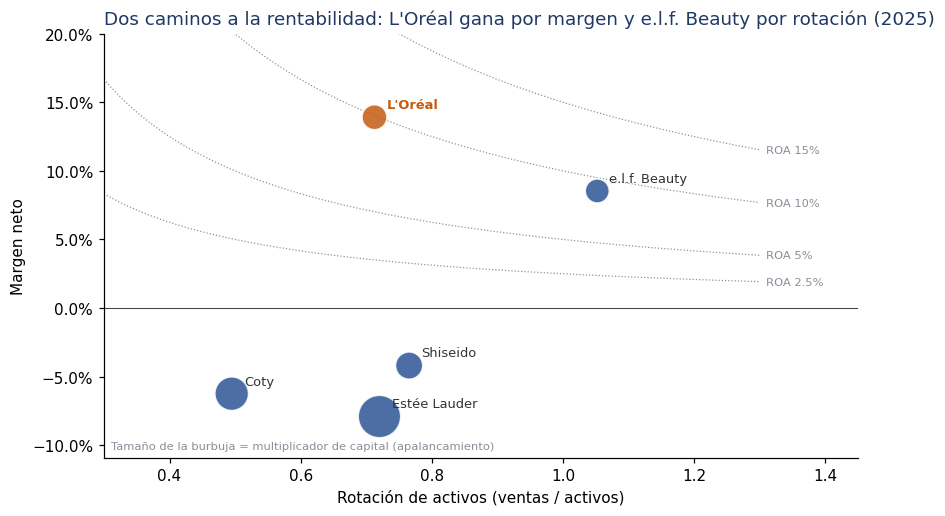

In [13]:
x, y = D_ult["Rotación"], D_ult["Margen neto"]

fig, ax = plt.subplots(figsize=(8, 4.8))
# Curvas de igual ROA: todos los puntos de una curva tienen el mismo ROA (= margen × rotación)
xs = np.linspace(0.3, 1.3, 200)
for roa in [0.025, 0.05, 0.10, 0.15]:
    ax.plot(xs, roa / xs, color=GREY, lw=0.8, ls=":")
    ax.text(1.31, roa / 1.3, f"ROA {roa:.1%}".replace(".0%", "%"), fontsize=7.5, color=GREY, va="center")
ax.axhline(0, color="#444", lw=0.7)

# Tamaño de la burbuja = multiplicador de capital (apalancamiento)
ax.scatter(x, y, s=150 * D_ult["Multiplicador"], alpha=0.85, edgecolor="white", zorder=3,
           color=[ACCENT if e == FOCO else BLUE for e in D_ult.index])
for e in D_ult.index:
    ax.annotate(e, (x[e], y[e]), xytext=(8, 6), textcoords="offset points", fontsize=8.5,
                color=ACCENT if e == FOCO else "#333", fontweight="bold" if e == FOCO else "normal")

ax.set_xlim(0.3, 1.45)
ax.set_ylim(min(y.min(), 0) - 0.03, max(0.20, y.max() + 0.03))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("Rotación de activos (ventas / activos)")
ax.set_ylabel("Margen neto")

sanas = D_ult[D_ult.ROA > 0]
por_margen, por_rotacion = sanas["Margen neto"].idxmax(), sanas["Rotación"].idxmax()
if por_margen != por_rotacion:
    titulo = f"Dos caminos a la rentabilidad: {por_margen} gana por margen y {por_rotacion} por rotación"
else:
    titulo = f"{por_margen} lidera tanto en margen como en rotación"
ax.set_title(f"{titulo} ({ANIO})")
ax.text(0.01, 0.02, "Tamaño de la burbuja = multiplicador de capital (apalancamiento)",
        transform=ax.transAxes, fontsize=7.5, color=GREY)
plt.tight_layout(); plt.show()

**Lectura del DuPont de tres factores.** El ROE de L'Oréal (17,5%) se explica por un margen neto
de 13,9%, una rotación de 0,71 y un multiplicador de 1,77. Su ROA de 9,9% —el más alto del grupo—
indica que la rentabilidad proviene de la calidad del negocio: su apalancamiento está por debajo
de la mediana (1,77 frente a 2,11).

El gráfico de margen versus rotación muestra dos caminos hacia la rentabilidad. L'Oréal y e.l.f.
alcanzan un ROA similar (9,9% y 9,0%) con estrategias opuestas: L'Oréal por **margen** y e.l.f. por
**rotación**. La brecha de ROE entre ambas (17,5% frente a 14,7%) se debe en parte al mayor
multiplicador de L'Oréal.

Las tres empresas con pérdidas no tienen un problema de eficiencia: Estée Lauder y Shiseido rotan
sus activos igual o más que L'Oréal. Su problema es el **margen**, que es negativo. Coty combina
margen negativo con la rotación más baja del grupo. Estée Lauder es el caso más riesgoso: su
multiplicador de 5,15 convierte un ROA de −5,7% en un ROE de −29,3%.

### 3.3 Nivel 3: DuPont de cinco factores

$$\text{ROE}=\underbrace{\frac{\text{UN}}{\text{UAI}}}_{\text{carga tributaria}}\times
\underbrace{\frac{\text{UAI}}{\text{EBIT}}}_{\text{carga de intereses}}\times
\underbrace{\frac{\text{EBIT}}{\text{Ventas}}}_{\text{margen EBIT}}\times
\underbrace{\frac{\text{Ventas}}{\text{Activos}}}_{\text{rotación}}\times
\underbrace{\frac{\text{Activos}}{\text{Patrimonio}}}_{\text{multiplicador}}$$

Separa el margen neto en **operación** (margen EBIT), **financiamiento** (carga de intereses) e
**impuestos** (carga tributaria). Las cargas se leen como "fracción que queda": una carga de
intereses de 0,95 significa que los intereses se llevan el 5% del resultado operacional.

**Cuidado:** si el EBIT o la UAI son negativos, las cargas pierden sentido (un cociente entre dos
números negativos puede ser mayor que 1). Esas empresas se marcan como **no interpretables** en las
cargas, aunque su margen EBIT, rotación y multiplicador sí se analizan.

In [14]:
def uai(df):
    # Utilidad antes de impuestos; si falta, se aproxima como EBIT − intereses
    return df["pretax_income"].fillna(df.ebit - df.interest_expense)


def dupont5(df):
    d = df[["empresa", "anio"]].copy()
    d["Carga tributaria"]   = df.net_income / uai(df)
    d["Carga de intereses"] = uai(df) / df.ebit
    d["Margen EBIT"]        = df.ebit / df.revenue
    d["Rotación"]           = df.revenue / df.total_assets
    d["Multiplicador"]      = df.total_assets / df.equity
    d["ROE"]                = d.iloc[:, 2:].prod(axis=1)
    d["Interpretable"]      = (df.ebit > 0) & (uai(df) > 0)
    return d


F5 = ["Carga tributaria", "Carga de intereses", "Margen EBIT", "Rotación", "Multiplicador"]
D5 = dupont5(panel)
D5_ult = D5[D5.anio == ANIO].set_index("empresa").drop(columns="anio")

assert np.allclose(D5_ult.ROE, corte.ROE), "El DuPont de cinco factores no reproduce el ROE"
print("Control OK: el producto de los cinco factores = ROE para todas las empresas.")
print("No interpretables en las cargas (EBIT o UAI negativos):",
      list(D5_ult.index[~D5_ult.Interpretable]))

ok = D5_ult.Interpretable
# Mediana: las cargas solo con empresas interpretables; el resto con todo el grupo
med5 = pd.Series({c: D5_ult.loc[ok, c].median() if c.startswith("Carga") else D5_ult[c].median()
                  for c in F5 + ["ROE"]})


def gris_no_interp(f):
    # Pinta en gris las cargas que no se pueden interpretar
    if f.name not in D5_ult.index or D5_ult.loc[f.name, "Interpretable"]:
        return ["" for _ in f]
    return ["color: #8A8F98; font-style: italic" if c.startswith("Carga") else "" for c in f.index]


tabla5 = pd.concat([D5_ult[F5 + ["ROE"]], med5.to_frame("Mediana del grupo").T])
(tabla5.style
     .format({"Carga tributaria": "{:.3f}", "Carga de intereses": "{:.3f}", "Margen EBIT": "{:.1%}",
              "Rotación": "{:.2f}", "Multiplicador": "{:.2f}", "ROE": "{:.1%}"})
     .apply(gris_no_interp, axis=1)
     .apply(lambda f: [f"font-weight: bold; color: {ACCENT}" if f.name == FOCO else "" for _ in f], axis=1)
     .set_caption(f"DuPont de cinco factores, {ANIO} (gris = carga no interpretable)"))

Control OK: el producto de los cinco factores = ROE para todas las empresas.
No interpretables en las cargas (EBIT o UAI negativos): ['Coty', 'Estée Lauder', 'Shiseido']


,Carga tributaria,Carga de intereses,Margen EBIT,Rotación,Multiplicador,ROE
Coty,1.067,2.927,-2.0%,0.49,3.23,-10.0%
Estée Lauder,1.089,1.523,-4.8%,0.72,5.15,-29.3%
L'Oréal,0.721,0.958,20.2%,0.71,1.77,17.5%
Shiseido,1.468,1.293,-2.2%,0.77,2.11,-6.8%
e.l.f. Beauty,0.770,0.897,12.3%,1.05,1.64,14.7%
Mediana del grupo,0.746,0.928,-2.0%,0.72,2.11,-6.8%


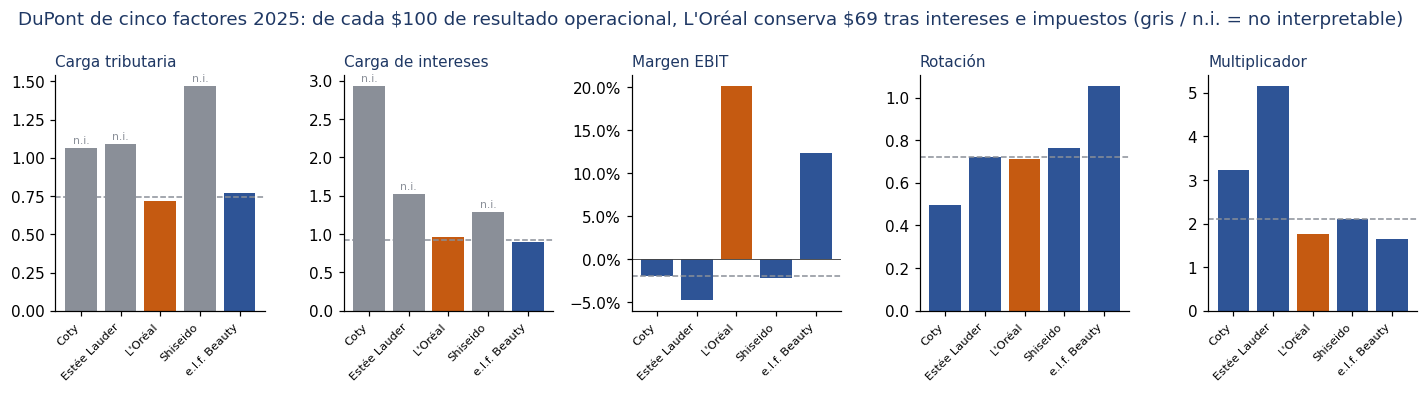

In [17]:
fig, axes = plt.subplots(1, 5, figsize=(13, 3.6))
for ax, c in zip(axes, F5):
    v = D5_ult[c].reindex(EMP)
    no_interp = c.startswith("Carga")
    colores = [GREY if (no_interp and not ok[e]) else (ACCENT if e == FOCO else BLUE) for e in v.index]
    ax.bar(v.index, v, color=colores)
    ax.axhline(med5[c], color=GREY, ls="--", lw=1)
    ax.axhline(0, color="#444", lw=0.6)
    for i, e in enumerate(v.index):
        if no_interp and not ok[e]:
            ax.text(i, max(v[e], 0) + 0.02 * abs(v).max(), "n.i.", ha="center", fontsize=7, color=GREY)
    ax.set_title(c, fontsize=10)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", fontsize=7.5)
    if c == "Margen EBIT":
        ax.yaxis.set_major_formatter(PercentFormatter(1.0))

f5 = D5_ult.loc[FOCO]
conserva = 100 * f5["Carga de intereses"] * f5["Carga tributaria"]
fig.suptitle(f"DuPont de cinco factores {ANIO}: de cada \\$100 de resultado operacional, {FOCO} conserva "
             f"\\${conserva:.0f} tras intereses e impuestos (gris / n.i. = no interpretable)",
             x=0.01, ha="left", color=NAVY)
plt.tight_layout(); plt.show()

In [16]:
ult = panel[panel.anio == ANIO].set_index("empresa").reindex(EMP)
u = uai(ult)

puente = pd.DataFrame({
    "Margen EBIT (operación)": ult.ebit / ult.revenue,
    "− Intereses":             -(ult.ebit - u) / ult.revenue,
    "− Impuestos y otros":     -(u - ult.net_income) / ult.revenue,
    "= Margen neto":           ult.net_income / ult.revenue,
})
assert np.allclose(puente.iloc[:, :3].sum(axis=1), puente["= Margen neto"])

(puente.style
     .format("{:+.1%}")
     .map(lambda v: f"color: {RED}" if v < 0 else "")
     .apply(lambda f: [f"font-weight: bold; background-color: rgba(197,90,17,0.15)" if f.name == FOCO else ""
                       for _ in f], axis=1)
     .set_caption(f"Puente del margen {ANIO}, en % de las ventas: de la operación a la utilidad neta"))

,Margen EBIT (operación),− Intereses,− Impuestos y otros,= Margen neto
empresa,,,,
Coty,-2.0%,-3.9%,-0.4%,-6.2%
Estée Lauder,-4.8%,-2.5%,-0.6%,-7.9%
L'Oréal,+20.2%,-0.9%,-5.4%,+13.9%
Shiseido,-2.2%,-0.6%,-1.3%,-4.2%
e.l.f. Beauty,+12.3%,-1.3%,-2.5%,+8.5%


**Lectura del DuPont de cinco factores.** De cada $100 de resultado operacional, L'Oréal conserva
$69 de utilidad neta: los intereses absorben solo el 4,2% del EBIT (carga de intereses 0,958) y su
tasa efectiva de impuestos es cercana al 28% (carga tributaria 0,721). Su ventaja frente a e.l.f.,
el otro par rentable, está en la operación (margen EBIT de 20,2% frente a 12,3%); e.l.f. además
destina una fracción mayor de su EBIT a intereses (10%).

En Coty, Estée Lauder y Shiseido las cargas no son interpretables porque su EBIT es negativo. El
puente del margen muestra que en las tres **la pérdida se origina en la operación**, y que en Coty
el gasto financiero (3,9% de las ventas) pesa incluso más que la pérdida operacional (2,0%),
reflejo de la deuda acumulada por sus adquisiciones. Coty y Shiseido registran además cargos
tributarios pese a sus pérdidas.

**Precaución:** el EBIT de yfinance incluye partidas no recurrentes (deterioros y
reestructuraciones), por lo que parte de las pérdidas operacionales podría no reflejar el
desempeño recurrente del negocio. El nivel 4 permite separar estos efectos.

### 3.4 Nivel 4: los motores operacionales

El nivel 4 deja de multiplicar y baja a las partidas que una gerencia puede gestionar:

- **Margen EBIT** = margen bruto − SG&A/ventas − depreciación/ventas − otros/ventas. El SG&A
  incluye marketing y publicidad, clave en la industria cosmética. "Otros" es el residuo: recoge
  deterioros de marcas, costos de reestructuración y resultados no operacionales incluidos en el
  EBIT de yfinance. Un residuo negativo indica que parte de la depreciación ya viene incluida en
  el costo de ventas o en el SG&A.
- **Rotación de activos**, explicada por los días de cobro (DSO), los días de inventario y la
  rotación de PP&E (ventas/PP&E): cobranza, gestión de inventario e inversión en plantas y tiendas.

In [18]:
def motores(df):
    m = df[["empresa", "anio"]].copy()
    m["Margen bruto"]      = df.gross_profit / df.revenue
    m["SG&A / ventas"]     = df.sga / df.revenue
    m["Dep. / ventas"]     = df.depreciation / df.revenue
    m["Margen EBIT"]       = df.ebit / df.revenue
    # Residuo del puente: deterioros, reestructuraciones y otros resultados incluidos en el EBIT
    m["Otros / ventas"]    = m["Margen bruto"] - m["SG&A / ventas"] - m["Dep. / ventas"] - m["Margen EBIT"]
    m["DSO (días)"]        = 365 * df.receivables / df.revenue
    m["Inventario (días)"] = 365 * df.inventory / df.cogs
    m["Ventas / PP&E"]     = df.revenue / df.ppe
    return m


M4 = motores(panel)
M4_ult = M4[M4.anio == ANIO].set_index("empresa").drop(columns="anio")

orden4 = ["Margen bruto", "SG&A / ventas", "Dep. / ventas", "Otros / ventas", "Margen EBIT",
          "DSO (días)", "Inventario (días)", "Ventas / PP&E"]
tabla4 = pd.concat([M4_ult[orden4], M4_ult[orden4].median().to_frame("Mediana del grupo").T])
pct4 = ["Margen bruto", "SG&A / ventas", "Dep. / ventas", "Otros / ventas", "Margen EBIT"]

(tabla4.style
     .format({**{c: "{:.1%}" for c in pct4}, "DSO (días)": "{:.0f}",
              "Inventario (días)": "{:.0f}", "Ventas / PP&E": "{:.2f}"})
     .apply(lambda f: [f"font-weight: bold; color: {ACCENT}" if f.name == FOCO
                       else ("font-style: italic" if f.name == "Mediana del grupo" else "")
                       for _ in f], axis=1)
     .set_caption(f"Motores operacionales {ANIO}: margen bruto − SG&A − depreciación − otros = margen EBIT"))

,Margen bruto,SG&A / ventas,Dep. / ventas,Otros / ventas,Margen EBIT,DSO (días),Inventario (días),Ventas / PP&E
Coty,64.8%,52.7%,7.1%,7.0%,-2.0%,33,140,6.04
Estée Lauder,74.0%,66.0%,5.8%,6.9%,-4.8%,39,203,2.80
L'Oréal,74.3%,51.0%,4.1%,-1.0%,20.2%,46,147,7.50
Shiseido,76.6%,74.8%,7.4%,-3.4%,-2.2%,61,237,2.61
e.l.f. Beauty,71.2%,59.2%,3.4%,-3.7%,12.3%,35,181,45.63
Mediana del grupo,74.0%,59.2%,5.8%,-1.0%,-2.0%,39,181,6.04


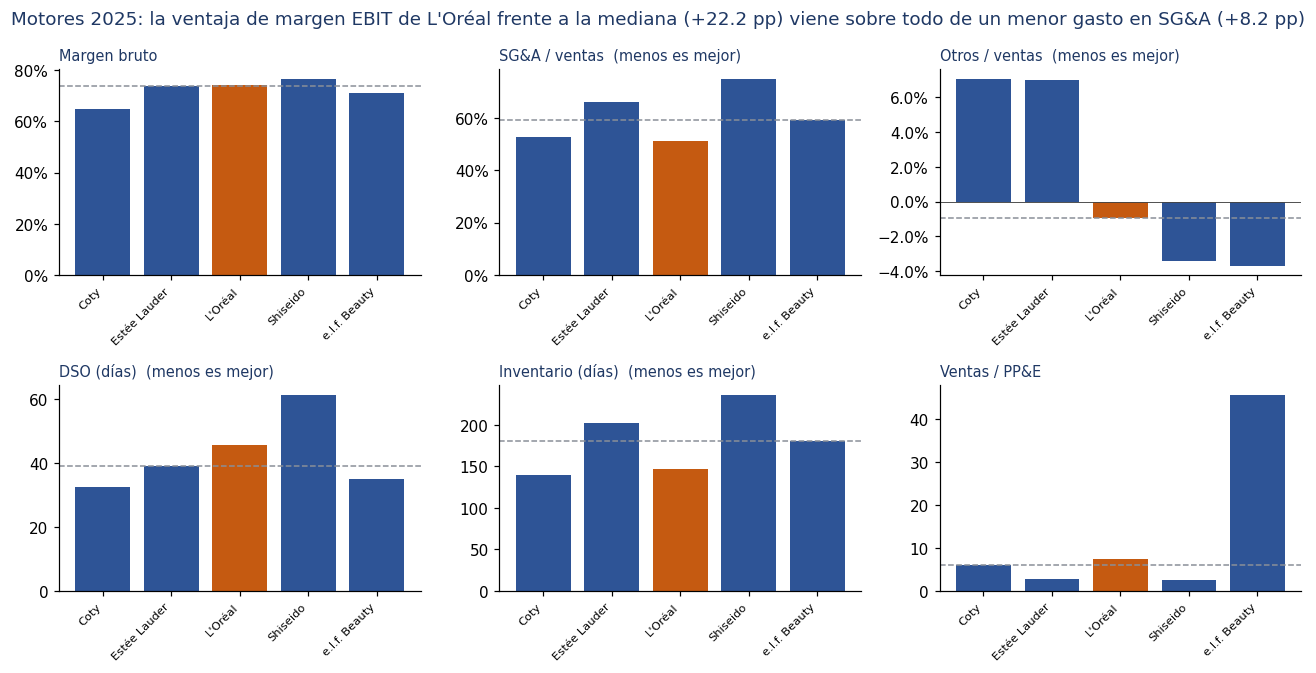

Ventaja de L'Oréal frente a la mediana, por partida (puntos porcentuales de margen):
el margen bruto                        0.300
un menor gasto en SG&A                 8.200
una menor depreciación                 1.700
menos cargos extraordinarios (otros)   0.000


In [19]:
MOT = ["Margen bruto", "SG&A / ventas", "Otros / ventas",
       "DSO (días)", "Inventario (días)", "Ventas / PP&E"]
MENOS_MEJOR4 = {"SG&A / ventas", "Otros / ventas", "DSO (días)", "Inventario (días)"}
med4 = M4_ult[MOT + ["Dep. / ventas", "Margen EBIT"]].median()

fig, axes = plt.subplots(2, 3, figsize=(12, 6.2))
for ax, c in zip(axes.flat, MOT):
    v = M4_ult[c].reindex(EMP)
    ax.bar(v.index, v, color=[ACCENT if e == FOCO else BLUE for e in v.index])
    ax.axhline(med4[c], color=GREY, ls="--", lw=1)
    ax.axhline(0, color="#444", lw=0.6)
    ax.set_title(c + ("  (menos es mejor)" if c in MENOS_MEJOR4 else ""), fontsize=9.5)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", fontsize=7.5)
    if c in pct4:
        ax.yaxis.set_major_formatter(PercentFormatter(1.0))

# Título que comunica: ¿qué partida explica más la ventaja de margen EBIT del foco frente a la mediana?
f4 = M4_ult.loc[FOCO]
ventaja = pd.Series({
    "el margen bruto":         f4["Margen bruto"] - med4["Margen bruto"],
    "un menor gasto en SG&A":  med4["SG&A / ventas"] - f4["SG&A / ventas"],
    "una menor depreciación":  med4["Dep. / ventas"] - f4["Dep. / ventas"],
    "menos cargos extraordinarios (otros)": med4["Otros / ventas"] - f4["Otros / ventas"],
})
principal = ventaja.idxmax()
fig.suptitle(f"Motores {ANIO}: la ventaja de margen EBIT de {FOCO} frente a la mediana "
             f"({100 * (f4['Margen EBIT'] - med4['Margen EBIT']):+.1f} pp) viene sobre todo de {principal} "
             f"({100 * ventaja.max():+.1f} pp)", x=0.01, ha="left", color=NAVY)
plt.tight_layout(); plt.show()

print("Ventaja de", FOCO, "frente a la mediana, por partida (puntos porcentuales de margen):")
print((100 * ventaja).round(1).to_string())

**Lectura de los motores operacionales.** El margen bruto es similar en todo el grupo (65–77%):
la ventaja de L'Oréal no está en fabricar más barato, sino en el **gasto de venta y administración**
(SG&A de 51% de las ventas, el más bajo del grupo, frente a 59% de e.l.f. y 75% de Shiseido). Frente
a e.l.f., el menor SG&A explica 8,2 de los 7,9 pp de diferencia en margen EBIT, una ventaja de escala
en marketing y estructura. Shiseido ilustra el caso opuesto: el mayor margen bruto del grupo
absorbido por gastos de venta.

El residuo "otros" confirma que las pérdidas de **Coty y Estée Lauder** se deben en buena parte a
**cargos extraordinarios** (≈7% de las ventas en ambas, coherente con deterioros y
reestructuraciones): sin ellos, su margen EBIT sería positivo. Los residuos negativos de Shiseido y
e.l.f. reflejan depreciación ya incluida en otras partidas.

En la rotación, L'Oréal mantiene inventarios más eficientes que la mediana (147 frente a 181 días),
pero cobra más lento (46 frente a 39 días). La alta rotación de e.l.f. se explica por su modelo
asset-light: al tercerizar la fabricación, genera 45,6 de ventas por cada peso de PP&E.

### 3.5 Atribución: ¿qué explica el cambio del ROE de L'Oréal?

Como el ROE es un producto de factores, el logaritmo lo convierte en una suma:

$$\ln\frac{\text{ROE}_t}{\text{ROE}_{t-1}} = \sum_i \ln\frac{f_{i,t}}{f_{i,t-1}}
\quad\Longrightarrow\quad
\text{Aporte}_i = \Delta\text{ROE}\cdot\frac{\ln(f_{i,t}/f_{i,t-1})}{\ln(\text{ROE}_t/\text{ROE}_{t-1})}$$

Los aportes suman exactamente ΔROE y no dependen del orden de los factores. El método exige que
todos los factores sean positivos en ambos años, condición que L'Oréal cumple en todo el período.
Se calcula la atribución para cada par de años consecutivos y se detalla el año de mayor cambio.

In [20]:
def atribucion(f_ant, f_act):
    # f_ant, f_act: Series con los cinco factores en t-1 y t (todos deben ser positivos)
    if (f_ant <= 0).any() or (f_act <= 0).any():
        raise ValueError("La atribución logarítmica exige factores positivos en ambos años")
    lr = np.log(f_act / f_ant)
    if np.isclose(lr.sum(), 0):                     # ROE sin cambio: no hay nada que repartir
        return lr * 0
    return (f_act.prod() - f_ant.prod()) * lr / lr.sum()


serie = D5[D5.empresa == FOCO].set_index("anio").sort_index()
filas, pares = {}, {}
for a1 in serie.index:
    a0 = a1 - 1
    if a0 not in serie.index:
        continue
    f_ant, f_act = serie.loc[a0, F5].astype(float), serie.loc[a1, F5].astype(float)
    aporte = atribucion(f_ant, f_act)
    assert np.isclose(aporte.sum(), f_act.prod() - f_ant.prod())
    etiqueta = f"{a0} → {a1}"
    pares[etiqueta] = (a0, a1)
    filas[etiqueta] = {"ROE inicial": f_ant.prod(), **aporte.to_dict(),
                       "Δ ROE": f_act.prod() - f_ant.prod(), "ROE final": f_act.prod()}

ATR = pd.DataFrame(filas).T
print(f"Control OK: en todos los años los aportes suman exactamente el cambio del ROE de {FOCO}.")

(ATR.style
     .format({"ROE inicial": "{:.1%}", "ROE final": "{:.1%}",
              **{c: lambda v: f"{100 * v:+.2f} pp" for c in F5 + ["Δ ROE"]}})
     .map(lambda v: f"color: {RED}" if v < 0 else f"color: {GREEN}", subset=F5 + ["Δ ROE"])
     .set_caption(f"{FOCO}: aporte de cada factor al cambio del ROE (puntos porcentuales)"))

Control OK: en todos los años los aportes suman exactamente el cambio del ROE de L'Oréal.


,ROE inicial,Carga tributaria,Carga de intereses,Margen EBIT,Rotación,Multiplicador,Δ ROE,ROE final
2022 → 2023,21.0%,+0.64 pp,-0.38 pp,-0.11 pp,-0.59 pp,+0.72 pp,+0.27 pp,21.3%
2023 → 2024,21.3%,-0.34 pp,-0.33 pp,+0.29 pp,-0.58 pp,-0.96 pp,-1.93 pp,19.3%
2024 → 2025,19.3%,-0.98 pp,+0.03 pp,-0.11 pp,-1.47 pp,+0.72 pp,-1.81 pp,17.5%


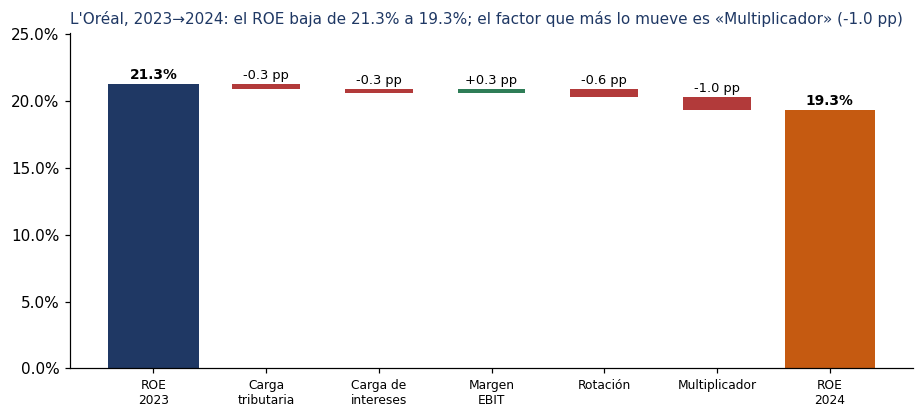

anio,2023,2024,Cambio
Margen bruto,73.9%,74.2%,+0.3 pp
SG&A / ventas,51.0%,51.1%,+0.1 pp
Dep. / ventas,4.2%,4.3%,+0.1 pp
Otros / ventas,-1.2%,-1.4%,-0.2 pp
Margen EBIT,20.0%,20.3%,+0.3 pp
DSO (días),45,47,+2 días
Inventario (días),152,151,-1 días
Ventas / PP&E,7.41,7.29,-0.12


In [23]:
caso = ATR["Δ ROE"].abs().idxmax()
a0, a1 = pares[caso]
f_ant, f_act = serie.loc[a0, F5].astype(float), serie.loc[a1, F5].astype(float)
aporte = ATR.loc[caso, F5].astype(float)
roe_ant, roe_act = f_ant.prod(), f_act.prod()

etiquetas = ([f"ROE\n{a0}"] +
             ["Carga\ntributaria", "Carga de\nintereses", "Margen\nEBIT", "Rotación", "Multiplicador"] +
             [f"ROE\n{a1}"])
fig, ax = plt.subplots(figsize=(8.5, 3.9))
ax.bar(0, roe_ant, color=NAVY)
nivel = tope = roe_ant
for i, v in enumerate(aporte.values, start=1):
    ax.bar(i, v, bottom=nivel, color=GREEN if v >= 0 else RED, width=0.6)
    ax.text(i, max(nivel, nivel + v) + 0.004, f"{100 * v:+.1f} pp", ha="center", fontsize=8.5)
    nivel += v
    tope = max(tope, nivel)
ax.bar(len(etiquetas) - 1, roe_act, color=ACCENT)
for x_, v in [(0, roe_ant), (len(etiquetas) - 1, roe_act)]:
    ax.text(x_, v + 0.004, f"{v:.1%}", ha="center", fontsize=9, fontweight="bold")
ax.set_xticks(range(len(etiquetas)), etiquetas, fontsize=8)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylim(0, 1.18 * max(roe_ant, roe_act, tope))
principal = aporte.abs().idxmax()
verbo = "sube" if roe_act > roe_ant else "baja"
ax.set_title(f"{FOCO}, {a0}→{a1}: el ROE {verbo} de {roe_ant:.1%} a {roe_act:.1%}; "
             f"el factor que más lo mueve es «{principal}» ({100 * aporte[principal]:+.1f} pp)", fontsize=10)
plt.tight_layout(); plt.show()

# Nivel 4 del mismo período: ¿qué partidas operacionales cambiaron?
m_foco = M4[M4.empresa == FOCO].set_index("anio").drop(columns="empresa")
cambio4 = m_foco.loc[[a0, a1], orden4].T
cambio4["Cambio"] = cambio4[a1] - cambio4[a0]
dias = ["DSO (días)", "Inventario (días)"]
(cambio4.style
     .format("{:.1%}", subset=pd.IndexSlice[pct4, [a0, a1]])
     .format(lambda v: f"{100 * v:+.1f} pp", subset=pd.IndexSlice[pct4, ["Cambio"]])
     .format("{:.0f}", subset=pd.IndexSlice[dias, [a0, a1]])
     .format("{:+.0f} días", subset=pd.IndexSlice[dias, ["Cambio"]])
     .format("{:.2f}", subset=pd.IndexSlice[["Ventas / PP&E"], [a0, a1]])
     .format("{:+.2f}", subset=pd.IndexSlice[["Ventas / PP&E"], ["Cambio"]])
     .set_caption(f"{FOCO}: motores operacionales {a0} vs. {a1}"))

**Lectura de la atribución y de los motores.** El ROE de L'Oréal cae de 21,0% (2022) a 17,5%
(2025), aunque sigue siendo el más alto del grupo. La caída **no proviene de la operación**: el
aporte del margen EBIT es prácticamente nulo en todos los años. El principal factor es la
**rotación de activos**, que resta rentabilidad todos los años (≈ −2,6 pp acumulados): los activos
crecen más rápido que las ventas. En 2025 se suma una mayor carga tributaria (−1,0 pp). El
multiplicador oscila (−1,0 pp en 2024 por menor endeudamiento, +0,7 pp en 2025), sin cambiar la
conclusión: la rentabilidad de L'Oréal sigue basada en el negocio y no en el apalancamiento.

Los motores operacionales de L'Oréal se mantienen prácticamente constantes: margen bruto
(+0,3 pp), SG&A (+0,1 pp), días de cobro (+2), días de inventario (−1) y rotación de PP&E (−0,12).
La operación y el capital de trabajo no explican la caída del ROE. Como la rotación total de
activos sí disminuye, el aumento de activos debe provenir de partidas fuera del ciclo operacional
(marcas, plusvalía, inversiones o caja). El common-size del balance (sección 4) permite
identificar cuáles.

## 4. Common-size: comparar empresas de distinto tamaño

El análisis **vertical** (common-size) expresa cada partida como porcentaje de una base: las
**ventas** en el estado de resultados y los **activos totales** en el balance. Así se comparan
estructuras de costos y de financiamiento entre empresas de tamaños y monedas muy distintos.

### 4.1 Estado de resultados common-size

,Costo de ventas,SG&A,Depreciación y otros,Intereses,Impuestos y otros,Utilidad neta
empresa,,,,,,
Coty,35.2%,52.7%,14.2%,3.9%,0.4%,-6.2%
Estée Lauder,26.0%,66.0%,12.7%,2.5%,0.6%,-7.9%
L'Oréal,25.7%,51.0%,3.2%,0.9%,5.4%,13.9%
Shiseido,23.4%,74.8%,4.0%,0.6%,1.3%,-4.2%
e.l.f. Beauty,28.8%,59.2%,-0.3%,1.3%,2.5%,8.5%


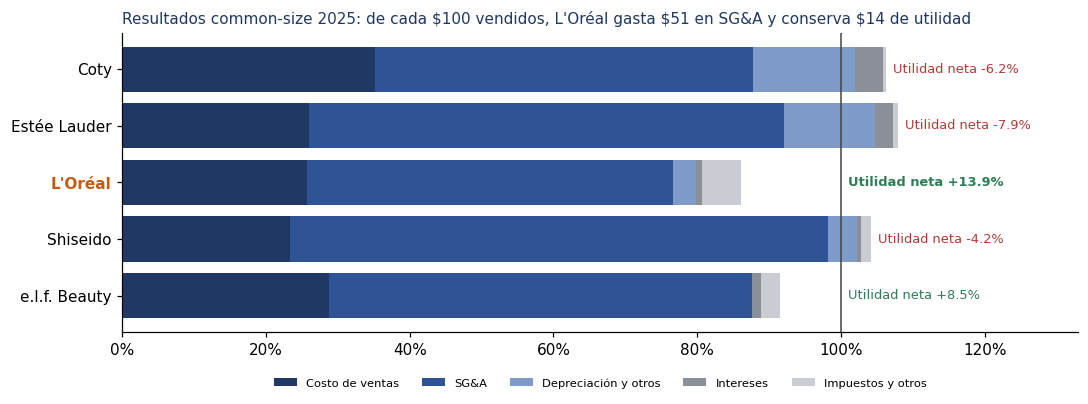

In [24]:
ult = panel[panel.anio == ANIO].set_index("empresa").reindex(EMP)
u_ = uai(ult)

cs_er = pd.DataFrame({
    "Costo de ventas":      ult.cogs,
    "SG&A":                 ult.sga,
    "Depreciación y otros": ult.gross_profit - ult.sga - ult.ebit,
    "Intereses":            ult.ebit - u_,
    "Impuestos y otros":    u_ - ult.net_income,
    "Utilidad neta":        ult.net_income,
}).div(ult.revenue, axis=0)
assert np.allclose(cs_er.sum(axis=1), 1), "Las partidas no suman 100% de las ventas"

display(cs_er.style.format("{:.1%}")
        .map(lambda v: f"color: {RED}" if v < 0 else "")
        .apply(lambda f: [f"font-weight: bold; color: {ACCENT}" if f.name == FOCO else "" for _ in f], axis=1)
        .set_caption(f"Estado de resultados common-size {ANIO} (% de las ventas)"))

# Barras apiladas: cada barra = 100% de las ventas; lo que sobrepasa el 100% es pérdida
COSTOS = list(cs_er.columns[:-1])
pal = [NAVY, BLUE, "#7F9CC9", GREY, "#C9CDD3"]
fig, ax = plt.subplots(figsize=(10, 3.8))
izq = np.zeros(len(cs_er))
for col, c in zip(COSTOS, pal):
    ax.barh(cs_er.index, cs_er[col], left=izq, color=c, label=col)
    izq += cs_er[col].values
ax.axvline(1, color="#444", lw=1)
for i, e in enumerate(cs_er.index):
    un = cs_er.loc[e, "Utilidad neta"]
    ax.text(max(izq[i], 1) + 0.01, i, f"Utilidad neta {un:+.1%}", va="center", fontsize=8.5,
            color=GREEN if un >= 0 else RED, fontweight="bold" if e == FOCO else "normal")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlim(0, 1.33)
ax.invert_yaxis()
for lbl in ax.get_yticklabels():
    if lbl.get_text() == FOCO:
        lbl.set_color(ACCENT); lbl.set_fontweight("bold")
ax.legend(ncol=5, fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
f_cs = cs_er.loc[FOCO]
ax.set_title(f"Resultados common-size {ANIO}: de cada \\$100 vendidos, {FOCO} gasta \\${100 * f_cs['SG&A']:.0f} "
             f"en SG&A y conserva \\${100 * f_cs['Utilidad neta']:.0f} de utilidad", fontsize=10)
plt.tight_layout(); plt.show()

### 4.2 Balance common-size del grupo

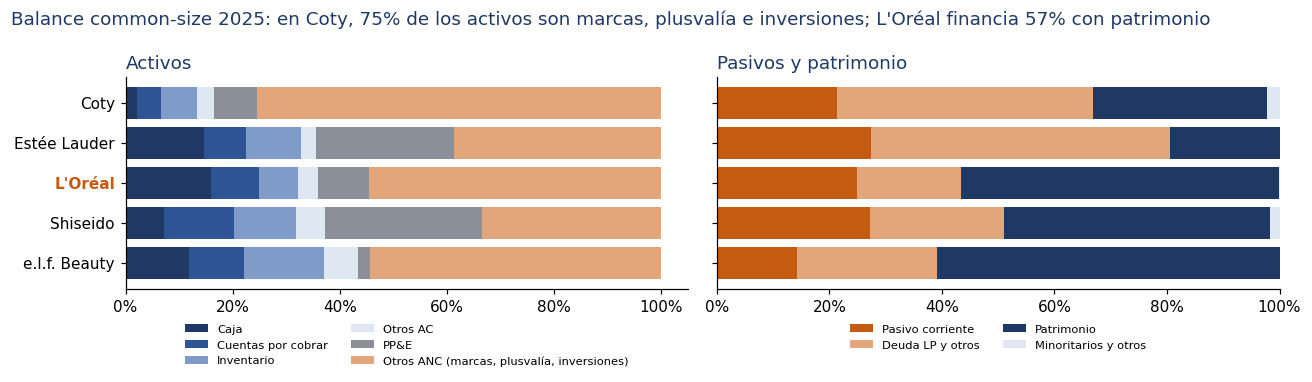

In [25]:
def common_size_balance(df):
    # Partidas que alguna empresa no reporta se tratan como 0
    comp = df[["cash", "receivables", "inventory", "ppe"]].fillna(0)
    activos = pd.DataFrame({
        "Caja": comp.cash, "Cuentas por cobrar": comp.receivables, "Inventario": comp.inventory,
        "Otros AC": df.current_assets - comp.cash - comp.receivables - comp.inventory,
        "PP&E": comp.ppe,
        "Otros ANC (marcas, plusvalía, inversiones)": df.total_assets - df.current_assets - comp.ppe})
    # total_liabilities excluye el interés minoritario y equity es solo el de los controladores
    pasivos = pd.DataFrame({
        "Pasivo corriente": df.current_liabilities,
        "Deuda LP y otros": df.total_liabilities - df.current_liabilities,
        "Patrimonio": df.equity,
        "Minoritarios y otros": df.total_assets - df.total_liabilities - df.equity})
    return activos.div(df.total_assets, axis=0), pasivos.div(df.total_assets, axis=0)


cs_act, cs_pas = common_size_balance(ult)
assert np.allclose(cs_act.sum(axis=1), 1) and np.allclose(cs_pas.sum(axis=1), 1)

display(pd.concat({"Activos": cs_act, "Pasivos y patrimonio": cs_pas}, axis=1).style.format("{:.1%}")
        .apply(lambda f: [f"font-weight: bold; color: {ACCENT}" if f.name == FOCO else "" for _ in f], axis=1)
        .set_caption(f"Balance common-size {ANIO} (% de los activos totales)"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
paletas = [[NAVY, BLUE, "#7F9CC9", LIGHT, GREY, "#E3A57A"], [ACCENT, "#E3A57A", NAVY, LIGHT]]
for ax, tabla, pal, tit in zip(axes, [cs_act, cs_pas], paletas, ["Activos", "Pasivos y patrimonio"]):
    izq = np.zeros(len(tabla))
    for col, c in zip(tabla.columns, pal):
        ax.barh(tabla.index, tabla[col], left=izq, color=c, label=col)
        izq += tabla[col].values
    ax.xaxis.set_major_formatter(PercentFormatter(1.0)); ax.set_title(tit)
    ax.legend(ncol=2, fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
axes[0].invert_yaxis()
for lbl in axes[0].get_yticklabels():
    if lbl.get_text() == FOCO:
        lbl.set_color(ACCENT); lbl.set_fontweight("bold")
anc_max = cs_act.iloc[:, 5].idxmax()
fig.suptitle(f"Balance common-size {ANIO}: en {anc_max}, {cs_act.iloc[:, 5].max():.0%} de los activos son "
             f"marcas, plusvalía e inversiones; {FOCO} financia {cs_pas.loc[FOCO, 'Patrimonio']:.0%} con patrimonio",
             x=0.01, ha="left", color=NAVY)
plt.tight_layout(); plt.show()

### 4.3 El balance de L'Oréal en el tiempo

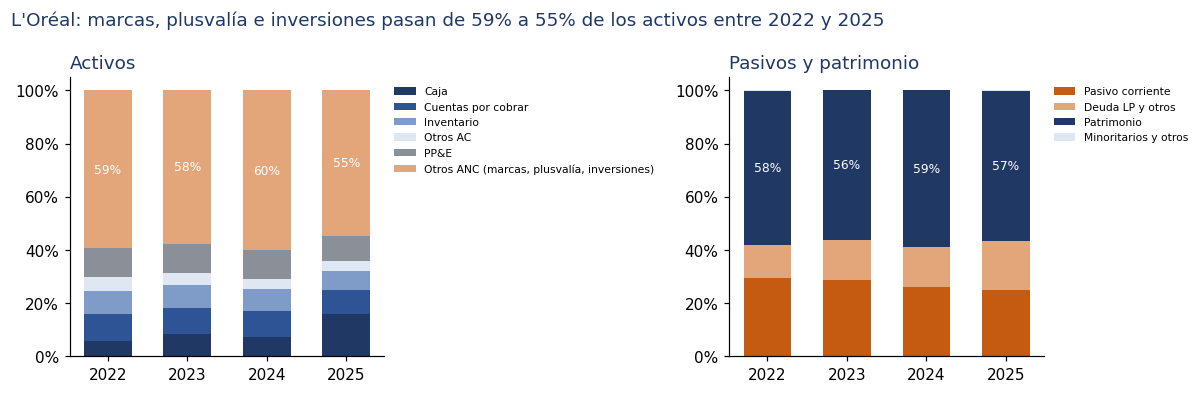

In [26]:
p_foco = panel[panel.empresa == FOCO].set_index("anio").sort_index()
cs_act_t, cs_pas_t = common_size_balance(p_foco)
anc = "Otros ANC (marcas, plusvalía, inversiones)"

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, tabla, pal, tit in zip(axes, [cs_act_t, cs_pas_t], paletas, ["Activos", "Pasivos y patrimonio"]):
    abajo = np.zeros(len(tabla))
    x = tabla.index.astype(str)
    for col, c in zip(tabla.columns, pal):
        ax.bar(x, tabla[col], bottom=abajo, color=c, label=col, width=0.6)
        if col in (anc, "Patrimonio"):
            for xi, b, h in zip(x, abajo, tabla[col]):
                ax.text(xi, b + h / 2, f"{h:.0%}", ha="center", va="center", fontsize=8, color="white")
        abajo += tabla[col].values
    ax.yaxis.set_major_formatter(PercentFormatter(1.0)); ax.set_title(tit)
    ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)

a_ini, a_fin = cs_act_t.index.min(), cs_act_t.index.max()
fig.suptitle(f"{FOCO}: marcas, plusvalía e inversiones pasan de {cs_act_t.loc[a_ini, anc]:.0%} a "
             f"{cs_act_t.loc[a_fin, anc]:.0%} de los activos entre {a_ini} y {a_fin}",
             x=0.01, ha="left", color=NAVY)
plt.tight_layout(); plt.show()

**Lectura del common-size.** En el estado de resultados, el SG&A (marketing, ventas y
administración) es la mayor partida en todo el grupo, lo que confirma que en cosmética el costo
clave es vender la marca, no fabricar el producto. L'Oréal conserva 14 de cada 100 vendidos; en
Coty, Estée Lauder y Shiseido los costos superan el 100% de las ventas, empujados por cargos
extraordinarios (Coty, Estée Lauder) o por un SG&A de 75% (Shiseido).

En el balance, las marcas, plusvalía e inversiones dominan los activos (55% en L'Oréal y 75% en
Coty, lo que explica la baja rotación de esta última). e.l.f. casi no tiene PP&E (2,3%), coherente
con su fabricación tercerizada. L'Oréal y e.l.f. financian más de la mitad de sus activos con
patrimonio, mientras Estée Lauder solo un 19%.

**Contraste de hipótesis.** La caída de la rotación de L'Oréal no se explica principalmente por
adquisiciones: los activos intangibles suben levemente en 2024 (58% → 60%) pero bajan en 2025
(55%). En 2025 la caja se duplica (de ~7% a 16% de los activos), junto con un mayor endeudamiento.
La caja acumulada infla los activos sin generar ventas, lo que explica la mayor caída de rotación
de ese año (−1,5 pp de ROE).

## 5. Tendencias: análisis horizontal

El análisis **horizontal** sigue cada partida en el tiempo:

- **Índice base 100**: $\text{Índice}_t = 100\cdot X_t / X_{\text{base}}$, con el primer año
  disponible de cada empresa como base, para comparar trayectorias de empresas de distinto tamaño.
- **CAGR** (crecimiento anual compuesto): $\left(X_T / X_0\right)^{1/T} - 1$.

Se compara el crecimiento de las **ventas** con el de los **activos**: si los activos crecen más
rápido, la rotación cae. **Nota:** el crecimiento está medido en la moneda de cada empresa (EUR,
USD o JPY), por lo que incluye efectos cambiarios, y los períodos difieren según el cierre fiscal.

### 5.1 Índice base 100 y CAGR

In [27]:
ventas  = panel.pivot(index="anio", columns="empresa", values="revenue")
activos = panel.pivot(index="anio", columns="empresa", values="total_assets")

# Base 100 = primer año disponible de cada empresa
indice = ventas.apply(lambda s: 100 * s / s.dropna().iloc[0])


def cagr(s):
    s = s.dropna()
    T = s.index[-1] - s.index[0]
    return (s.iloc[-1] / s.iloc[0]) ** (1 / T) - 1


def periodo(s):
    s = s.dropna()
    return f"{s.index[0]}–{s.index[-1]}"


crec = pd.DataFrame({
    "Período":      ventas.apply(periodo),
    "Moneda":       panel.groupby("empresa").moneda.first(),
    "CAGR ventas":  ventas.apply(cagr),
    "CAGR activos": activos.apply(cagr),
})
crec["Ventas − activos"] = crec["CAGR ventas"] - crec["CAGR activos"]
crec = crec.sort_values("CAGR ventas", ascending=False)

(crec.style
     .format({"CAGR ventas": "{:+.1%}", "CAGR activos": "{:+.1%}",
              "Ventas − activos": lambda v: f"{100 * v:+.1f} pp"})
     .map(lambda v: f"color: {RED}" if v < 0 else f"color: {GREEN}", subset=["Ventas − activos"])
     .apply(lambda f: [f"font-weight: bold; color: {ACCENT}" if f.name == FOCO else "" for _ in f], axis=1)
     .set_caption("Crecimiento anual compuesto (si ventas − activos < 0, la rotación cae)"))

,Período,Moneda,CAGR ventas,CAGR activos,Ventas − activos
empresa,,,,,
e.l.f. Beauty,2023–2026,USD,+41.4%,+59.0%,-17.6 pp
L'Oréal,2022–2025,EUR,+4.8%,+9.7%,-4.9 pp
Coty,2023–2026,USD,+1.5%,-7.0%,+8.4 pp
Estée Lauder,2023–2026,USD,-1.8%,-5.5%,+3.7 pp
Shiseido,2022–2025,JPY,-3.1%,-1.0%,-2.1 pp


### 5.2 Gráfico de tendencias

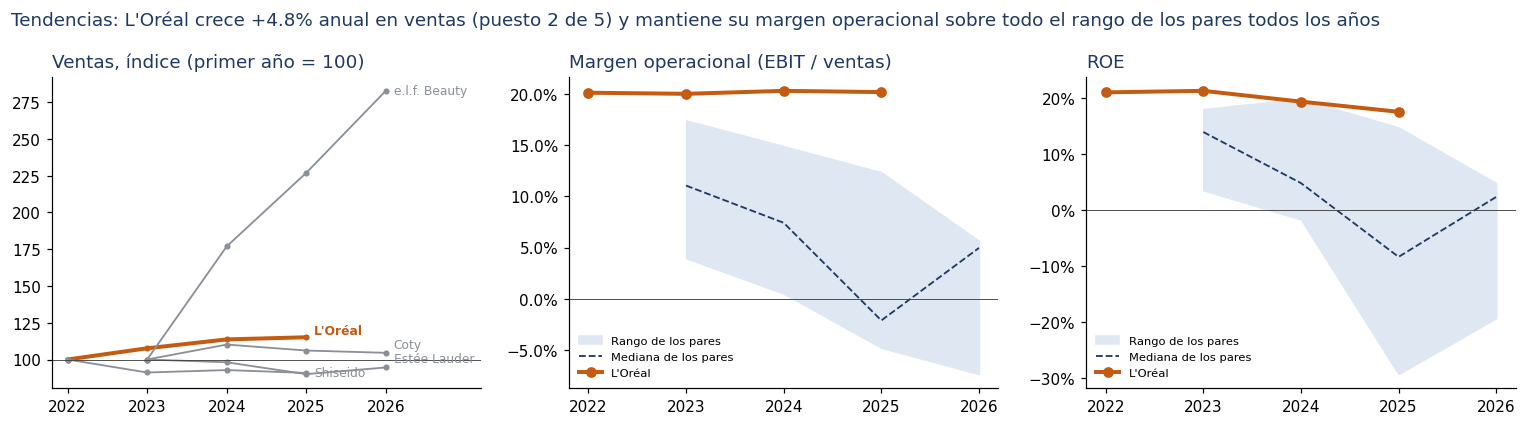

In [28]:
pares = [e for e in EMP if e != FOCO]


def banda(piv, min_pares=3):
    # Rango y mediana de los pares, solo en años con suficientes pares con datos
    sub = piv[pares]
    ok_ = sub.notna().sum(axis=1) >= min_pares
    return sub.min(axis=1)[ok_], sub.max(axis=1)[ok_], sub.median(axis=1)[ok_]


mop = R.pivot(index="anio", columns="empresa", values="Margen operacional")
roe = R.pivot(index="anio", columns="empresa", values="ROE")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))

# (1) Ventas, índice base 100
ax = axes[0]
ult_val = {e: indice[e].dropna().iloc[-1] for e in EMP}
ult_x = {e: indice[e].dropna().index[-1] for e in EMP}
pos = separar(ult_val, gap=0.05 * (indice.max().max() - indice.min().min()))
for e in EMP:
    s = indice[e].dropna()
    ax.plot(s.index, s, marker="o", ms=3, lw=2.6 if e == FOCO else 1.2, color=ACCENT if e == FOCO else GREY)
    ax.text(ult_x[e] + 0.1, pos[e], e, fontsize=8, va="center",
            color=ACCENT if e == FOCO else GREY, fontweight="bold" if e == FOCO else "normal")
ax.axhline(100, color="#444", lw=0.6)
ax.set_xticks(indice.index); ax.set_xlim(indice.index.min() - 0.2, indice.index.max() + 1.2)
ax.set_title("Ventas, índice (primer año = 100)")

# (2) y (3) Margen operacional y ROE: foco frente al rango y la mediana de los pares
for ax, piv, tit in [(axes[1], mop, "Margen operacional (EBIT / ventas)"), (axes[2], roe, "ROE")]:
    lo, hi, med = banda(piv)
    ax.fill_between(lo.index, lo, hi, color=LIGHT, label="Rango de los pares")
    ax.plot(med.index, med, color=NAVY, ls="--", lw=1.2, label="Mediana de los pares")
    s = piv[FOCO].dropna()
    ax.plot(s.index, s, color=ACCENT, marker="o", lw=2.6, label=FOCO)
    ax.axhline(0, color="#444", lw=0.6)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0)); ax.set_xticks(piv.index)
    ax.set_title(tit); ax.legend(fontsize=7.5, frameon=False, loc="lower left")

# Título que comunica
c_foco = crec.loc[FOCO, "CAGR ventas"]
puesto = list(crec.index).index(FOCO) + 1
lo_m, hi_m, med_m = banda(mop)
comunes = s.index.intersection(med_m.index)
sobre = (mop.loc[comunes, FOCO] > hi_m[comunes]).all()
texto_margen = "sobre todo el rango de los pares" if sobre else "sobre la mediana de los pares"
fig.suptitle(f"Tendencias: {FOCO} crece {c_foco:+.1%} anual en ventas (puesto {puesto} de {len(crec)}) "
             f"y mantiene su margen operacional {texto_margen} todos los años",
             x=0.01, ha="left", color=NAVY)
plt.tight_layout(); plt.show()

**Lectura de las tendencias.** e.l.f. es el caso de mayor crecimiento (ventas +41% anual), pero sus
activos crecen aún más rápido (+59%), coherente con la adquisición de Rhode. L'Oréal crece de forma
moderada y estable (+4,8% anual en euros), con activos que crecen más rápido que las ventas
(−4,9 pp), lo que confirma la caída de rotación identificada en el DuPont. Coty, Estée Lauder y
Shiseido no crecen; en Coty y Estée Lauder los activos se reducen por desinversiones y deterioros,
por lo que su mejora de rotación no refleja un mejor desempeño.

El margen operacional de L'Oréal se mantiene en torno a 20% en todo el período y siempre sobre el
rango de los pares, mientras la mediana del grupo cae de ~11% (2023) a −2% (2025). Su ROE desciende
gradualmente (de 21% a 17,5%), pero se mantiene sobre los pares en todo el período. En síntesis, en
un ciclo de deterioro del sector, L'Oréal destaca por su **estabilidad**. Los datos de 2026 incluyen
solo tres pares y deben leerse con cautela.

## 6. Peer screening: comparar con criterios explícitos

El *peer screening* tiene dos decisiones:

1. **Elegir el grupo de comparación**: misma industria, tamaño comparable, modelo de negocio
   similar. Un grupo mal elegido invalida cualquier conclusión.
2. **Comparar con medidas robustas**: con pocos pares la media es muy sensible a extremos, así
   que se prefieren la **mediana**, los **percentiles** y los **z-scores** (con winsorización).

Un detalle clave es la **orientación**: en la mayoría de los ratios más es mejor, pero en
Deuda/Patrimonio o en los días de cobro, menos es mejor. Antes de combinar ratios se invierte el
signo de estos últimos.

### 6.1 Mapa de calor por percentiles

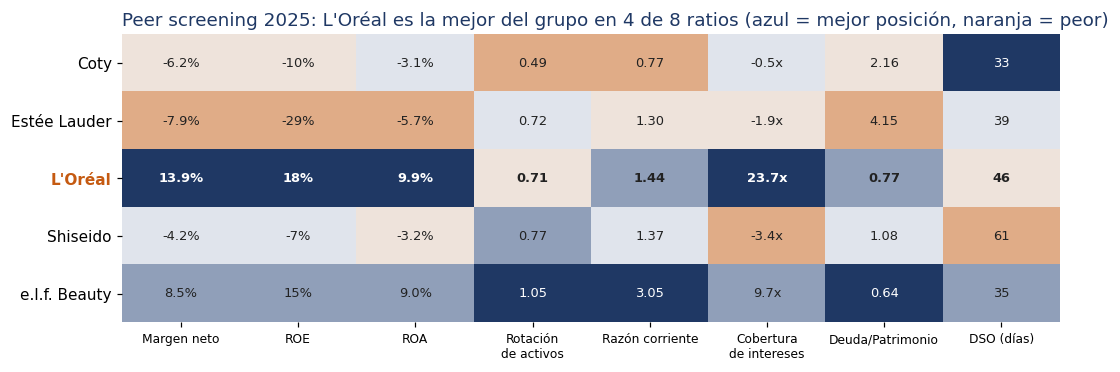

In [29]:
COLS = ["Margen neto", "ROE", "ROA", "Rotación de activos", "Razón corriente",
        "Cobertura de intereses", "Deuda/Patrimonio", "DSO (días)"]
MENOS_ES_MEJOR6 = {"Deuda/Patrimonio", "DSO (días)"}


def orientar(t):
    # Invierte el signo de los ratios donde menos es mejor (así, mayor = mejor en todos)
    return t.apply(lambda s: -s if s.name in MENOS_ES_MEJOR6 else s)


def percentiles(t):
    return orientar(t).rank(pct=True)


def zscores(t, lim=2.5):
    x = orientar(t)
    return ((x - x.median()) / x.std(ddof=0)).clip(-lim, lim)   # winsorización simple


X = corte[COLS].reindex(EMP)
pct, z = percentiles(X), zscores(X)

fmt6 = {"Margen neto": "{:.1%}", "ROE": "{:.0%}", "ROA": "{:.1%}", "Rotación de activos": "{:.2f}",
        "Razón corriente": "{:.2f}", "Cobertura de intereses": "{:.1f}x", "Deuda/Patrimonio": "{:.2f}",
        "DSO (días)": "{:.0f}"}
cmap = LinearSegmentedColormap.from_list("uai", [ACCENT, "#F3E3D6", "#DCE5F2", NAVY])

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.imshow(pct.values, cmap=cmap, vmin=0, vmax=1, aspect="auto")
for i, e in enumerate(pct.index):
    for j, c in enumerate(COLS):
        r, g_, b, _ = cmap(float(pct.iloc[i, j]))
        oscuro = 0.299 * r + 0.587 * g_ + 0.114 * b < 0.55
        ax.text(j, i, fmt6[c].format(X.loc[e, c]), ha="center", va="center", fontsize=8.5,
                color="white" if oscuro else "#222", fontweight="bold" if e == FOCO else "normal")
ax.set_xticks(range(len(COLS)), [c.replace(" de ", "\nde ") for c in COLS], fontsize=8)
ax.set_yticks(range(len(pct)), pct.index)
for lbl in ax.get_yticklabels():
    if lbl.get_text() == FOCO:
        lbl.set_color(ACCENT); lbl.set_fontweight("bold")
n_top = int((pct.loc[FOCO] == pct.max()).sum())
ax.set_title(f"Peer screening {ANIO}: {FOCO} es la mejor del grupo en {n_top} de {len(COLS)} ratios "
             f"(azul = mejor posición, naranja = peor)")
for s in ax.spines.values():
    s.set_visible(False)
plt.show()

### 6.2 Del screening al ranking

Hay dos formas habituales de pasar de la tabla a una decisión:

- **Filtros**: umbrales fijos que una empresa debe cumplir (cobertura de intereses > 3x y razón
  corriente > 0,8). Son transparentes, pero binarios.
- **Puntaje compuesto**: un promedio ponderado de percentiles o z-scores. Los pesos son una
  decisión del analista y deben justificarse. Se calcula con ambos métodos para verificar que el
  orden no dependa del método elegido.

,Puntaje (percentiles),Puntaje (z-scores),Pasa filtros,Puesto (percentiles),Puesto (z-scores)
empresa,,,,,
L'Oréal,0.87,+1.24,True,1,2
e.l.f. Beauty,0.86,+1.33,True,2,1
Shiseido,0.52,-0.13,False,3,3
Coty,0.44,-0.34,False,4,4
Estée Lauder,0.31,-0.65,False,5,5


El orden del ranking CAMBIA entre percentiles y z-scores.


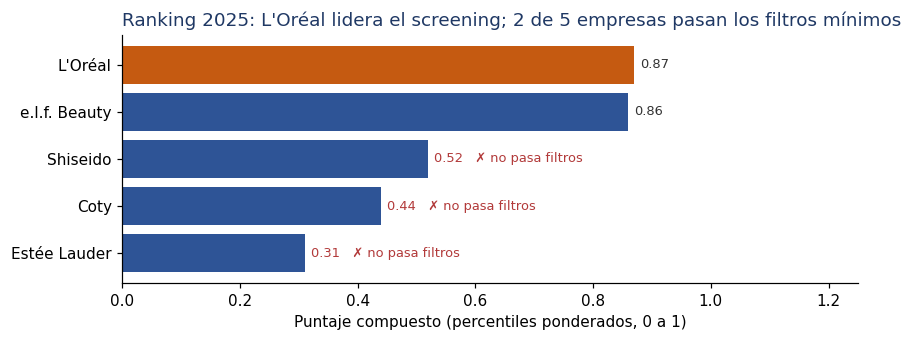

In [30]:
PESOS = {"Margen neto": 0.20, "ROE": 0.20, "ROA": 0.10, "Rotación de activos": 0.10,
         "Razón corriente": 0.10, "Cobertura de intereses": 0.15, "Deuda/Patrimonio": 0.10, "DSO (días)": 0.05}
assert abs(sum(PESOS.values()) - 1) < 1e-9
w = pd.Series(PESOS)

filtros = (X["Cobertura de intereses"] > 3) & (X["Razón corriente"] > 0.8)
ranking = pd.DataFrame({
    "Puntaje (percentiles)": (pct * w).sum(axis=1),
    "Puntaje (z-scores)":    (z * w).sum(axis=1),
    "Pasa filtros":          filtros,
})
ranking["Puesto (percentiles)"] = ranking["Puntaje (percentiles)"].rank(ascending=False, method="min").astype(int)
ranking["Puesto (z-scores)"]    = ranking["Puntaje (z-scores)"].rank(ascending=False, method="min").astype(int)
ranking = ranking.sort_values("Puntaje (percentiles)", ascending=False)

display(ranking.style
        .format({"Puntaje (percentiles)": "{:.2f}", "Puntaje (z-scores)": "{:+.2f}"})
        .apply(lambda f: [f"font-weight: bold; color: {ACCENT}" if f.name == FOCO else "" for _ in f], axis=1)
        .set_caption(f"Ranking {ANIO} (filtros: cobertura de intereses > 3x y razón corriente > 0,8)"))

mismo = (ranking["Puesto (percentiles)"] == ranking["Puesto (z-scores)"]).all()
print("El orden del ranking", "COINCIDE" if mismo else "CAMBIA", "entre percentiles y z-scores.")

fig, ax = plt.subplots(figsize=(8, 3.2))
v = ranking["Puntaje (percentiles)"]
ax.barh(v.index, v, color=[ACCENT if e == FOCO else BLUE for e in v.index],
        alpha=1.0 if True else 0.4)
for i, e in enumerate(v.index):
    txt = f"{v[e]:.2f}" + ("" if ranking.loc[e, "Pasa filtros"] else "   ✗ no pasa filtros")
    ax.text(v[e] + 0.01, i, txt, va="center", fontsize=8.5,
            color="#333" if ranking.loc[e, "Pasa filtros"] else RED)
ax.invert_yaxis(); ax.set_xlim(0, 1.25); ax.set_xlabel("Puntaje compuesto (percentiles ponderados, 0 a 1)")
ax.set_title(f"Ranking {ANIO}: {ranking.index[0]} lidera el screening; "
             f"{int(filtros.sum())} de {len(filtros)} empresas pasan los filtros mínimos")
plt.tight_layout(); plt.show()

### 6.3 Sensibilidad del ranking a los pesos

Como los dos primeros lugares quedan muy cerca, se recalcula el ranking con cuatro esquemas de
pesos (base, pesos iguales, enfoque en rentabilidad y enfoque en riesgo).

In [31]:
ESCENARIOS = {
    "Base (profesor)":      PESOS,
    "Pesos iguales":        {c: 1 / len(COLS) for c in COLS},
    "Enfoque rentabilidad": {"Margen neto": .25, "ROE": .25, "ROA": .20, "Rotación de activos": .05,
                             "Razón corriente": .05, "Cobertura de intereses": .10, "Deuda/Patrimonio": .05,
                             "DSO (días)": .05},
    "Enfoque riesgo":       {"Margen neto": .10, "ROE": .10, "ROA": .10, "Rotación de activos": .05,
                             "Razón corriente": .20, "Cobertura de intereses": .20, "Deuda/Patrimonio": .20,
                             "DSO (días)": .05},
}
assert all(abs(sum(v.values()) - 1) < 1e-9 for v in ESCENARIOS.values())

sens = pd.DataFrame({k: (pct * pd.Series(v)).sum(axis=1) for k, v in ESCENARIOS.items()})
puestos = sens.rank(ascending=False, method="min").astype(int)

display(sens.style.format("{:.2f}").highlight_max(axis=0, props=f"font-weight: bold; color: {ACCENT}")
        .set_caption("Puntaje compuesto según el esquema de pesos (percentiles)"))
display(puestos.style.set_caption("Puesto en el ranking según el esquema de pesos"))
print("Ganador por escenario:", sens.idxmax().to_dict())

,Base (profesor),Pesos iguales,Enfoque rentabilidad,Enfoque riesgo
empresa,,,,
Coty,0.44,0.47,0.47,0.44
Estée Lauder,0.31,0.35,0.27,0.32
L'Oréal,0.87,0.80,0.92,0.86
Shiseido,0.52,0.50,0.51,0.49
e.l.f. Beauty,0.86,0.88,0.83,0.89


,Base (profesor),Pesos iguales,Enfoque rentabilidad,Enfoque riesgo
empresa,,,,
Coty,4,4,4,4
Estée Lauder,5,5,5,5
L'Oréal,1,2,1,2
Shiseido,3,3,3,3
e.l.f. Beauty,2,1,2,1


Ganador por escenario: {'Base (profesor)': "L'Oréal", 'Pesos iguales': 'e.l.f. Beauty', 'Enfoque rentabilidad': "L'Oréal", 'Enfoque riesgo': 'e.l.f. Beauty'}


**Lectura del peer screening.** L'Oréal es la mejor del grupo en rentabilidad (margen neto, ROE,
ROA) y en cobertura de intereses; e.l.f. lo es en rotación, liquidez y endeudamiento. Con los pesos
base, L'Oréal encabeza el ranking por percentiles (0,87), prácticamente empatada con e.l.f.
(0,86); con z-scores el orden se invierte, porque este método premia la gran distancia de e.l.f. en
liquidez (razón corriente 3,05 frente a ~1,3 del resto). El análisis de sensibilidad confirma el
empate: L'Oréal lidera cuando se prioriza la rentabilidad y e.l.f. cuando se prioriza la solidez
del balance.

La conclusión robusta es la separación del grupo en dos bloques: **L'Oréal y e.l.f.** comparten el
primer lugar, mientras **Shiseido, Coty y Estée Lauder** ocupan los puestos 3 a 5 en todos los
métodos y escenarios, y ninguna pasa los filtros mínimos (cobertura de intereses > 3x y razón
corriente > 0,8).

**Justificación de los pesos.** Se mantiene el esquema base (60% rentabilidad y capacidad de pago,
40% eficiencia y balance) por estar orientado a un inversionista en acciones, cuyo retorno depende
principalmente de la rentabilidad. Los escenarios alternativos se reportan para transparentar la
sensibilidad del resultado.

## 7. Calidad de las utilidades: accruals

La utilidad contable incluye ingresos y gastos que aún no se convierten en caja (**accruals**).
Accruals altos o crecientes indican que la utilidad depende de estimaciones y de partidas que
podrían no materializarse. Dos formas de medirlos:

- **Desde el flujo de caja**: $\text{Accruals} = \text{UN} - \text{CFO}$.
- **Desde el balance** (Sloan, 1996): $(\Delta\text{AC}-\Delta\text{Caja})-(\Delta\text{PC}-\Delta\text{Deuda CP})-\text{Dep.}$

En ambos casos se dividen por los **activos promedio** para comparar empresas y años.

empresa,Coty,Estée Lauder,L'Oréal,Shiseido,e.l.f. Beauty
anio,,,,,
2023,–,–,-2.9%,-5.2%,–
2024,-4.2%,-8.7%,-3.5%,-4.6%,6.6%
2025,-7.2%,-11.6%,-4.3%,-11.6%,-1.8%
2026,-10.3%,-8.0%,–,–,-10.2%


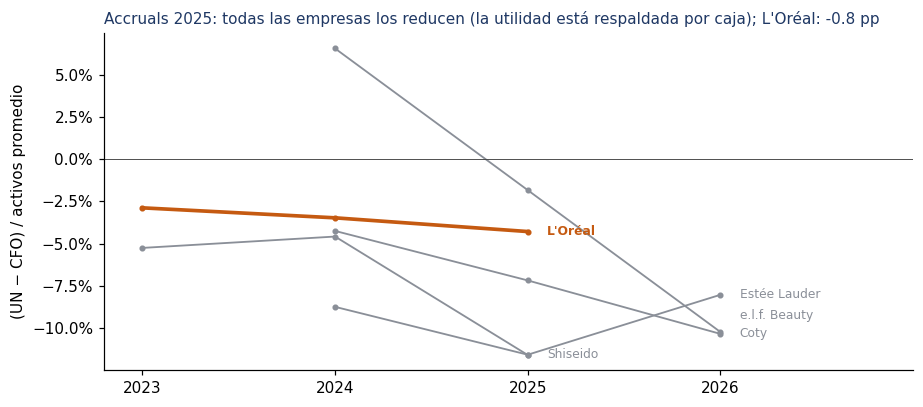

Variación de accruals en 2025 (pp):
empresa
Coty            -2.900
Estée Lauder    -2.800
L'Oréal         -0.800
Shiseido        -7.000
e.l.f. Beauty   -8.400

Correlación entre ambas medidas: 0.21


In [33]:
p = panel.set_index(["empresa", "anio"]).sort_index()
g = p.groupby(level="empresa")
activos_prom = (p.total_assets + g.total_assets.shift(1)) / 2

acc_flujo = (p.net_income - p.cfo) / activos_prom
# Versión de balance (Sloan): se asume ΔDeuda CP = 0, porque el panel no la separa
acc_balance = ((g.current_assets.diff() - g.cash.diff()) - g.current_liabilities.diff()
               - p.depreciation) / activos_prom

accruals = pd.DataFrame({"Flujo de caja": acc_flujo, "Balance": acc_balance}).dropna()
acc_t = accruals["Flujo de caja"].unstack("empresa").sort_index()          # años en orden
display(acc_t.style.format("{:.1%}", na_rep="–").set_caption("Ratio de accruals: (UN − CFO) / activos promedio"))

salto = (acc_t.loc[ANIO] - acc_t.loc[ANIO - 1]).reindex(EMP)   # variación en el año común
destacada = salto.idxmax()

fig, ax = plt.subplots(figsize=(8.5, 3.8))
ult_v = {e: acc_t[e].dropna().iloc[-1] for e in EMP}
pos = separar(ult_v, gap=0.06 * (acc_t.max().max() - acc_t.min().min()))
for e in EMP:
    s = acc_t[e].dropna()
    color = ACCENT if e == FOCO else (RED if (e == destacada and salto.max() > 0) else GREY)
    ax.plot(s.index, s, marker="o", ms=3, lw=2.4 if color != GREY else 1.2, color=color)
    ax.text(s.index[-1] + 0.1, pos[e], e, fontsize=8, va="center", color=color,
            fontweight="bold" if e == FOCO else "normal")
ax.axhline(0, color="#444", lw=0.6)
ax.yaxis.set_major_formatter(PercentFormatter(1.0)); ax.set_xticks(acc_t.index)
ax.set_xlim(acc_t.index.min() - 0.2, acc_t.index.max() + 1.0)
ax.set_ylabel("(UN − CFO) / activos promedio")

if salto.max() > 0:
    titulo = (f"Accruals: {destacada} tiene el mayor aumento en {ANIO} ({100 * salto.max():+.1f} pp); "
              f"{FOCO}: {100 * salto[FOCO]:+.1f} pp")
else:
    titulo = (f"Accruals {ANIO}: todas las empresas los reducen (la utilidad está respaldada por caja); "
              f"{FOCO}: {100 * salto[FOCO]:+.1f} pp")
ax.set_title(titulo, fontsize=10)
plt.tight_layout(); plt.show()

print("Variación de accruals en", ANIO, "(pp):")
print((100 * salto).round(1).to_string())
print("\nCorrelación entre ambas medidas:", f"{accruals.corr().iloc[0, 1]:.2f}")

**Lectura de los accruals.** En 2025 el ratio de accruals es negativo en todas las empresas y
disminuye respecto de 2024: en todo el grupo el flujo de caja operacional supera a la utilidad
contable, por lo que no hay señales de utilidades sin respaldo de caja. L'Oréal muestra valores
moderados y estables (−2,9% a −4,3%), propios de utilidades de buena calidad. Los valores muy
negativos de Estée Lauder y Shiseido (−11,6%) no reflejan mayor calidad, sino cargos sin efecto en
caja (deterioros) que deprimen la utilidad. El único registro positivo del período es e.l.f. en
2024 (+6,6%), coherente con la acumulación de capital de trabajo de una empresa en fuerte
crecimiento; se normaliza en los años siguientes. Se privilegia la medida basada en el flujo de
caja, ya que la versión de balance depende de simplificaciones (correlación entre ambas: 0,21).

## 8. Beneish M-Score

El modelo de Beneish (1999) combina ocho índices que comparan el año actual ($t$) con el anterior
($t-1$). Cada índice captura un incentivo o una huella típica de la manipulación de utilidades:

| Índice | Fórmula (t vs. t−1) | Señal de alerta |
|---|---|---|
| DSRI | (CxC/Ventas)$_t$ / (CxC/Ventas)$_{t-1}$ | > 1: ventas a crédito crecen más que las ventas |
| GMI | Margen bruto$_{t-1}$ / Margen bruto$_t$ | > 1: el margen se deteriora |
| AQI | [1 − (AC + PP&E)/AT]$_t$ / [·]$_{t-1}$ | > 1: más costos capitalizados como activo |
| SGI | Ventas$_t$ / Ventas$_{t-1}$ | alto: el crecimiento presiona las cifras |
| DEPI | tasa de depreciación$_{t-1}$ / tasa$_t$ | > 1: se deprecia más lento |
| SGAI | (SGA/Ventas)$_t$ / (SGA/Ventas)$_{t-1}$ | > 1: gastos crecen más que ventas |
| LVGI | ((Deuda LP + PC)/AT)$_t$ / (·)$_{t-1}$ | > 1: más deuda e incentivos por covenants |
| TATA | (UN − CFO) / AT$_t$ | alto: utilidad poco respaldada por caja |

$$M = -4{,}84 + 0{,}920\,\text{DSRI} + 0{,}528\,\text{GMI} + 0{,}404\,\text{AQI} + 0{,}892\,\text{SGI}
+ 0{,}115\,\text{DEPI} - 0{,}172\,\text{SGAI} + 4{,}679\,\text{TATA} - 0{,}327\,\text{LVGI}$$

Umbral habitual: $M > -1{,}78$ sugiere mayor probabilidad de manipulación ($-2{,}22$ es el umbral
conservador). El modelo tiende a dar **falsos positivos** en empresas de crecimiento acelerado.
Se detalla el aporte de cada índice para L'Oréal y para la empresa con el mayor M-Score de 2025.

anio,2023,2024,2025,2026
empresa,,,,
Coty,–,-2.49,-2.65,-3.02
Estée Lauder,–,-2.75,-3.22,-2.89
L'Oréal,-2.59,-2.51,-2.75,–
Shiseido,-2.87,-2.66,-3.01,–
e.l.f. Beauty,–,-1.63,-2.46,-2.58


L'Oréal, 2025: M = -2.75 → no supera el umbral de −1,78


,Índice,Coeficiente,Aporte
SGI,1.013,0.892,0.904
DSRI,0.969,0.920,0.892
GMI,0.998,0.528,0.527
AQI,0.907,0.404,0.366
DEPI,1.004,0.115,0.115
SGAI,0.998,-0.172,-0.172
TATA,-0.041,4.679,-0.191
LVGI,1.078,-0.327,-0.352


e.l.f. Beauty, 2025: M = -2.46 → no supera el umbral de −1,78


,Índice,Coeficiente,Aporte
SGI,1.283,0.892,1.144
DSRI,0.793,0.920,0.730
GMI,0.993,0.528,0.524
AQI,0.962,0.404,0.389
DEPI,1.129,0.115,0.130
TATA,-0.017,4.679,-0.082
SGAI,1.055,-0.172,-0.182
LVGI,0.851,-0.327,-0.278


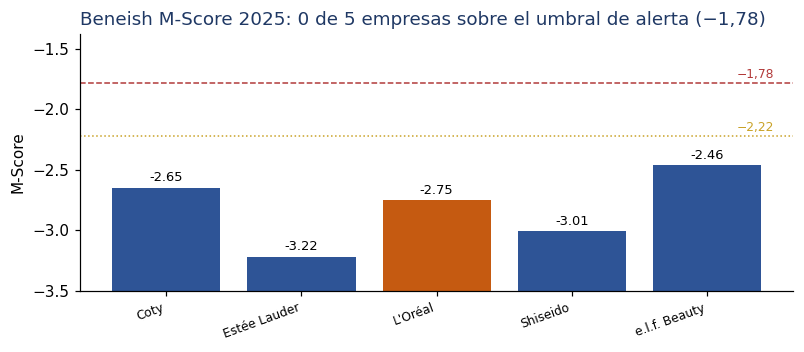

In [34]:
def beneish_indices(t, a):
    # t: fila del año actual; a: fila del año anterior
    tasa_dep = lambda x: x.depreciation / (x.depreciation + x.ppe)
    return pd.Series({
        "DSRI": (t.receivables / t.revenue) / (a.receivables / a.revenue),
        "GMI":  (a.gross_profit / a.revenue) / (t.gross_profit / t.revenue),
        "AQI":  (1 - (t.current_assets + t.ppe) / t.total_assets) / (1 - (a.current_assets + a.ppe) / a.total_assets),
        "SGI":  t.revenue / a.revenue,
        "DEPI": tasa_dep(a) / tasa_dep(t),
        "SGAI": (t.sga / t.revenue) / (a.sga / a.revenue),
        "LVGI": ((t.long_term_debt + t.current_liabilities) / t.total_assets)
                / ((a.long_term_debt + a.current_liabilities) / a.total_assets),
        "TATA": (t.net_income - t.cfo) / t.total_assets,
    })


COEF = pd.Series({"DSRI": 0.920, "GMI": 0.528, "AQI": 0.404, "SGI": 0.892, "DEPI": 0.115,
                  "SGAI": -0.172, "LVGI": -0.327, "TATA": 4.679})
CONST = -4.84


def m_score(idx):
    return CONST + (COEF * idx[COEF.index]).sum()


filas = []
for (e, anio), t in p.iterrows():
    if (e, anio - 1) in p.index:
        idx = beneish_indices(t, p.loc[(e, anio - 1)])
        filas.append({"empresa": e, "anio": anio, **idx, "M": m_score(idx)})
BEN = pd.DataFrame(filas).set_index(["empresa", "anio"])

display(BEN["M"].unstack("anio").style.format("{:.2f}", na_rep="–")
        .map(lambda v: f"color: {RED}; font-weight: bold" if pd.notna(v) and v > -1.78 else "")
        .set_caption("Beneish M-Score por año (rojo = sobre el umbral −1,78)"))

m_ult = BEN.xs(ANIO, level="anio")["M"].reindex(EMP)
caso_b = m_ult.idxmax()
for emp in dict.fromkeys([FOCO, caso_b]):
    fila = BEN.loc[(emp, ANIO)]
    det = pd.DataFrame({"Índice": fila[COEF.index], "Coeficiente": COEF, "Aporte": fila[COEF.index] * COEF})
    print(f"{emp}, {ANIO}: M = {fila.M:.2f} → {'SUPERA' if fila.M > -1.78 else 'no supera'} el umbral de −1,78")
    display(det.sort_values("Aporte", ascending=False).style.format("{:.3f}"))

base = -3.5
fig, ax = plt.subplots(figsize=(7.5, 3.3))
ax.bar(m_ult.index, m_ult - base, bottom=base,
       color=[RED if v > -1.78 else (ACCENT if e == FOCO else BLUE) for e, v in m_ult.items()])
for i, v in enumerate(m_ult):
    ax.text(i, v + 0.05, f"{v:.2f}", ha="center", fontsize=8.5)
ax.axhline(-1.78, color=RED, ls="--", lw=1); ax.axhline(-2.22, color=AMBER, ls=":", lw=1)
ax.text(len(m_ult) - 0.5, -1.74, "−1,78", color=RED, fontsize=8, ha="right")
ax.text(len(m_ult) - 0.5, -2.18, "−2,22", color=AMBER, fontsize=8, ha="right")
ax.set_ylim(base, max(m_ult.max(), -1.78) + 0.4); ax.set_ylabel("M-Score")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right", fontsize=8)
n_alerta = int((m_ult > -1.78).sum())
ax.set_title(f"Beneish M-Score {ANIO}: {n_alerta} de {len(m_ult)} empresas sobre el umbral de alerta (−1,78)")
plt.tight_layout(); plt.show()

**Lectura del Beneish M-Score.** En 2025 ninguna empresa supera el umbral de alerta (−1,78) ni el
conservador (−2,22). L'Oréal se mantiene lejos del umbral en todo el período (entre −2,51 y −2,75),
con índices cercanos a 1: sus ventas, cobranza, márgenes y gastos no muestran cambios bruscos. Sus
desviaciones son coherentes con lo observado en el balance: menor proporción de activos intangibles
(AQI 0,91) y mayor endeudamiento en 2025 (LVGI 1,08).

La única alerta del período es e.l.f. en 2024 (M = −1,63), año en que sus ventas crecieron ~77% y
sus accruals fueron positivos (+6,6%). Es el patrón típico de un falso positivo por crecimiento
legítimo, una limitación conocida del modelo, y la señal no persiste en 2025 y 2026. Coty, Estée
Lauder y Shiseido registran valores bajos pese a sus pérdidas: el modelo detecta utilidades
infladas, mientras estas empresas registran cargos que las reducen. Su riesgo principal es de
solvencia, no de manipulación.

## 9. Riesgo de insolvencia: Altman Z y Z''

**Z original (1968, manufactureras con acciones transadas):**
$Z = 1{,}2X_1 + 1{,}4X_2 + 3{,}3X_3 + 0{,}6X_4 + 1{,}0X_5$, con zonas: quiebra < 1,81; segura > 2,99.

**Z'' (no manufactureras):** $Z'' = 6{,}56X_1 + 3{,}26X_2 + 6{,}72X_3 + 1{,}05X_4$, con zonas:
quiebra < 1,10; segura > 2,60.

| Variable | Definición |
|---|---|
| $X_1$ | Capital de trabajo / activos |
| $X_2$ | Utilidades retenidas / activos |
| $X_3$ | EBIT / activos |
| $X_4$ | Z: capitalización bursátil / pasivo total · Z'': patrimonio contable / pasivo total |
| $X_5$ | Ventas / activos (solo en Z) |

Las empresas de cosmética no son manufactureras en sentido estricto (venden marca más que
producción), por lo que el **Z''** es la versión de referencia; el Z original se reporta como
contraste.

,Z,Z'',Zona Z,Zona Z''
empresa,,,,
Coty,0.09,-1.34,Quiebra,Quiebra
Estée Lauder,2.62,2.47,Gris,Gris
L'Oréal,5.84,3.38,Segura,Segura
Shiseido,2.03,2.34,Gris,Gris
e.l.f. Beauty,5.93,3.95,Segura,Segura


empresa,Coty,Estée Lauder,L'Oréal,Shiseido,e.l.f. Beauty
anio,,,,,
2022,–,–,3.00,2.87,–
2023,-0.63,3.58,2.98,2.78,2.94
2024,-0.88,3.39,3.13,2.27,2.48
2025,-1.34,2.47,3.38,2.34,3.95
2026,-2.08,2.87,–,–,2.20


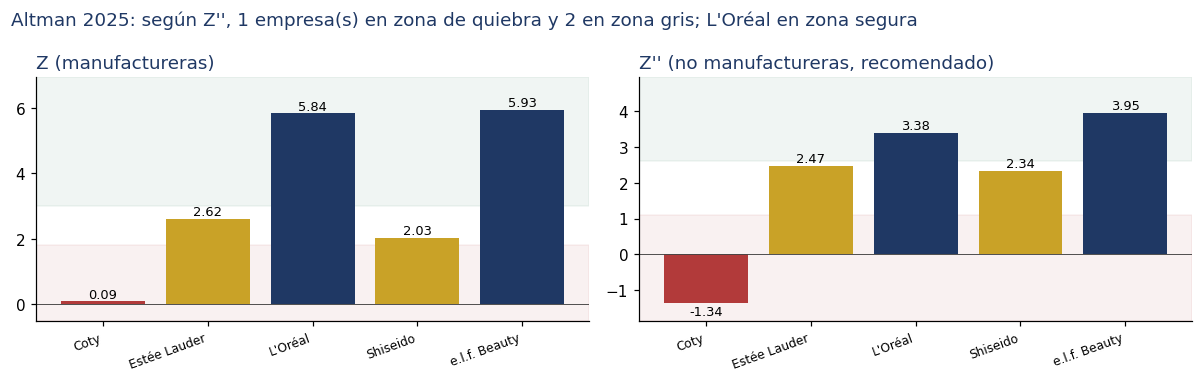

In [35]:
def altman(df):
    x1 = (df.current_assets - df.current_liabilities) / df.total_assets
    x2 = df.retained_earnings / df.total_assets
    x3 = df.ebit / df.total_assets
    x5 = df.revenue / df.total_assets
    z  = 1.2 * x1 + 1.4 * x2 + 3.3 * x3 + 0.6 * df.market_cap / df.total_liabilities + 1.0 * x5
    z2 = 6.56 * x1 + 3.26 * x2 + 6.72 * x3 + 1.05 * df.equity / df.total_liabilities
    return pd.DataFrame({"Z": z, "Z''": z2})


def zona(v, bajo, alto):
    return "Quiebra" if v < bajo else ("Gris" if v < alto else "Segura")


AZ = altman(p)
az_ult = AZ.xs(ANIO, level="anio").reindex(EMP)
az_ult["Zona Z"]   = az_ult["Z"].apply(zona, args=(1.81, 2.99))
az_ult["Zona Z''"] = az_ult["Z''"].apply(zona, args=(1.10, 2.60))
display(az_ult.style.format({"Z": "{:.2f}", "Z''": "{:.2f}"}).set_caption(f"Altman {ANIO}"))
display(AZ["Z''"].unstack("empresa").style.format("{:.2f}", na_rep="–").set_caption("Altman Z'' por año"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, col, (lo, hi) in zip(axes, ["Z", "Z''"], [(1.81, 2.99), (1.10, 2.60)]):
    v = az_ult[col]
    ax.bar(v.index, v, color=[RED if x < lo else (AMBER if x < hi else NAVY) for x in v], zorder=2)
    ax.axhspan(min(v.min(), 0) - 0.5, lo, color=RED, alpha=0.07, zorder=0)
    ax.axhspan(hi, v.max() + 1, color=GREEN, alpha=0.07, zorder=0)
    ax.axhline(0, color="#444", lw=0.6)
    for i, x in enumerate(v):
        ax.text(i, x + (0.1 if x >= 0 else -0.35), f"{x:.2f}", ha="center", fontsize=8.5)
    ax.set_ylim(min(v.min(), 0) - 0.5, v.max() + 1)
    ax.set_title(f"{col} {'(manufactureras)' if col == 'Z' else '(no manufactureras, recomendado)'}")
    plt.setp(ax.get_xticklabels(), rotation=20, ha="right", fontsize=8)
n_q = int((az_ult["Zona Z''"] == "Quiebra").sum()); n_g = int((az_ult["Zona Z''"] == "Gris").sum())
fig.suptitle(f"Altman {ANIO}: según Z'', {n_q} empresa(s) en zona de quiebra y {n_g} en zona gris; "
             f"{FOCO} en zona {az_ult.loc[FOCO, 'Zona Z' + chr(39) * 2].lower()}",
             x=0.01, ha="left", color=NAVY)
plt.tight_layout(); plt.show()

**Lectura del Altman Z''.** A diferencia del retail, en cosmética el Z original y el Z'' coinciden
en la clasificación de todas las empresas: la baja rotación del sector no infla el puntaje. En
2025, L'Oréal (3,38) y e.l.f. (3,95) se ubican en zona segura; Estée Lauder (2,47) y Shiseido
(2,34) en zona gris; y Coty en zona de quiebra (−1,34).

La evolución temporal refuerza el diagnóstico. Coty empeora todos los años (de −0,63 en 2023 a
−2,08 en 2026), consistente con su liquidez insuficiente, su EBIT negativo y el peso de su deuda: es
la señal de riesgo más fuerte del grupo, aunque no implica una quiebra inminente. Estée Lauder y
Shiseido pasan de zona segura a zona gris. L'Oréal es la única empresa cuyo Z'' mejora en el
período (de 3,00 a 3,38). e.l.f., la más sólida en 2025, cae a zona gris en 2026 (2,20), coherente
con el financiamiento de la adquisición de Rhode: un riesgo a monitorear.

## 10. Tablero de alertas

Cada señal mira un riesgo distinto: los **accruals** y el **M-Score** apuntan a la calidad de
las utilidades; el **Z''** apunta a la solvencia. Un tablero tipo semáforo las reúne en una vista
que un tomador de decisiones lee de inmediato.

| Señal | Alerta | Vigilar |
|---|---|---|
| Accruals (variación vs. año anterior) | > +2 pp | > +1,5 pp |
| Beneish M-Score | > −1,78 | > −2,22 |
| Altman Z'' | < 1,10 | < 2,60 |

Ninguna señal prueba nada por sí sola: indican **dónde mirar con más detalle**.

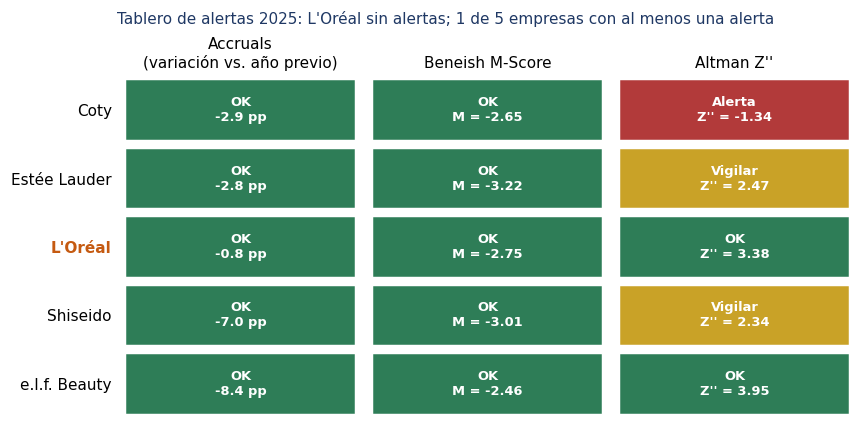

,Accruals,Beneish,Altman Z''
Coty,OK,OK,Alerta
Estée Lauder,OK,OK,Vigilar
L'Oréal,OK,OK,OK
Shiseido,OK,OK,Vigilar
e.l.f. Beauty,OK,OK,OK


In [36]:
def semaforo(valor, alerta, vigilar, mayor_es_peor=True):
    if mayor_es_peor:
        return "Alerta" if valor > alerta else ("Vigilar" if valor > vigilar else "OK")
    return "Alerta" if valor < alerta else ("Vigilar" if valor < vigilar else "OK")


tablero = pd.DataFrame(index=EMP)
tablero["Accruals"]   = salto * 100
tablero["Beneish"]    = m_ult
tablero["Altman Z''"] = az_ult["Z''"]
estado = pd.DataFrame({
    "Accruals":   tablero["Accruals"].apply(semaforo, args=(2.0, 1.5)),
    "Beneish":    tablero["Beneish"].apply(semaforo, args=(-1.78, -2.22)),
    "Altman Z''": tablero["Altman Z''"].apply(semaforo, args=(1.10, 2.60, False)),
}, index=EMP)

COL_EST = {"OK": GREEN, "Vigilar": AMBER, "Alerta": RED}
fmt_t = {"Accruals": "{:+.1f} pp", "Beneish": "M = {:.2f}", "Altman Z''": "Z'' = {:.2f}"}
fig, ax = plt.subplots(figsize=(8, 0.6 * len(EMP) + 1.0))
for i, e in enumerate(EMP):
    for j, c in enumerate(estado.columns):
        ax.add_patch(plt.Rectangle((j + 0.04, i + 0.08), 0.92, 0.84, color=COL_EST[estado.loc[e, c]]))
        ax.text(j + 0.5, i + 0.5, f"{estado.loc[e, c]}\n{fmt_t[c].format(tablero.loc[e, c])}",
                ha="center", va="center", color="white", fontsize=8.5, fontweight="bold")
ax.set_xlim(0, len(estado.columns)); ax.set_ylim(len(EMP), 0)
ax.set_xticks(np.arange(len(estado.columns)) + 0.5,
              ["Accruals\n(variación vs. año previo)", "Beneish M-Score", "Altman Z''"]); ax.xaxis.tick_top()
ax.set_yticks(np.arange(len(EMP)) + 0.5, EMP)
for lbl in ax.get_yticklabels():
    if lbl.get_text() == FOCO:
        lbl.set_color(ACCENT); lbl.set_fontweight("bold")
for s in ax.spines.values():
    s.set_visible(False)
ax.tick_params(length=0)
n_alertas = (estado == "Alerta").sum(axis=1)
ax.set_title(f"Tablero de alertas {ANIO}: {FOCO} {'sin alertas' if n_alertas[FOCO] == 0 else f'con {n_alertas[FOCO]} alerta(s)'}; "
             f"{int((n_alertas > 0).sum())} de {len(EMP)} empresas con al menos una alerta", pad=34, fontsize=10)
plt.tight_layout(); plt.show()
estado

**Lectura del tablero de alertas.** En 2025 ninguna empresa presenta señales de deterioro en la
calidad de sus utilidades: los accruals disminuyen en todo el grupo y ningún M-Score supera los
umbrales de Beneish. Las alertas se concentran en la **solvencia**: Coty se ubica en zona de quiebra
según el Altman Z'' (con deterioro sostenido desde 2023), mientras Estée Lauder y Shiseido requieren
vigilancia (zona gris). L'Oréal y e.l.f. no presentan alertas en 2025. Sin embargo, el tablero es
una foto de un año: e.l.f. registró una alerta Beneish en 2024 (asociada a su crecimiento) y su Z''
cae a zona gris en 2026 tras la adquisición de Rhode, mientras L'Oréal se mantiene sin alertas en
todo el período. Ninguna señal prueba nada por sí sola: indican dónde mirar con más detalle.

## 11. Dashboard interactivo en Streamlit

La celda 11.1 crea el archivo `app_dashboard.py` con un dashboard en **Streamlit**: el usuario elige
la empresa, el año y los pares, y la aplicación recalcula los ratios, el DuPont de tres y cinco
factores, la atribución del cambio del ROE y las señales de alerta (Beneish M-Score y Altman Z'').
La celda 11.2 lo ejecuta desde Colab y genera un enlace temporal para abrirlo en el navegador.

Para ejecutarlo fuera de Colab, desde una terminal en esta carpeta:
`pip install streamlit plotly` y luego `streamlit run app_dashboard.py`.
El dashboard lee `panel_para_dashboard.csv`, generado en la sección 1.

### 11.1 Crear el archivo del dashboard

In [38]:
%%writefile app_dashboard.py
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import streamlit as st

st.set_page_config(page_title="Screener de cosmética", page_icon="💄", layout="wide")

NAVY, BLUE, ACCENT, GREY = "#1F3864", "#2E5496", "#C55A11", "#8A8F98"
GREEN, RED, AMBER = "#2E7D57", "#B23A3A", "#C9A227"
F3 = ["Margen neto", "Rotación", "Multiplicador", "ROE"]
F5 = ["Carga tributaria", "Carga de intereses", "Margen EBIT", "Rotación", "Multiplicador"]
COEF = {"DSRI": 0.920, "GMI": 0.528, "AQI": 0.404, "SGI": 0.892, "DEPI": 0.115,
        "SGAI": -0.172, "LVGI": -0.327, "TATA": 4.679}
COLOR_ZONA = {"Quiebra": RED, "Alerta": RED, "Gris": AMBER, "Vigilar": AMBER,
              "Segura": GREEN, "OK": GREEN, "s/d": GREY}


# ---------------------------------------------------------------- cálculos
@st.cache_data
def cargar(archivo):
    return pd.read_csv(archivo)


def calcular(df):
    uai = df["pretax_income"].fillna(df.ebit - df.interest_expense)
    r = df[["empresa", "anio"]].copy()
    r["ROE"]                    = df.net_income / df.equity
    r["ROA"]                    = df.net_income / df.total_assets
    r["Margen neto"]            = df.net_income / df.revenue
    r["Rotación"]               = df.revenue / df.total_assets
    r["Multiplicador"]          = df.total_assets / df.equity
    r["Carga tributaria"]       = df.net_income / uai
    r["Carga de intereses"]     = uai / df.ebit
    r["Margen EBIT"]            = df.ebit / df.revenue
    r["Interpretable"]          = (df.ebit > 0) & (uai > 0)
    r["Margen bruto"]           = df.gross_profit / df.revenue
    r["SG&A / ventas"]          = df.sga / df.revenue
    r["Razón corriente"]        = df.current_assets / df.current_liabilities
    r["Deuda/Patrimonio"]       = df.total_liabilities / df.equity
    r["Cobertura de intereses"] = df.ebit / df.interest_expense
    r["DSO (días)"]             = 365 * df.receivables / df.revenue
    r["Inventario (días)"]      = 365 * df.inventory / df.cogs
    x1 = (df.current_assets - df.current_liabilities) / df.total_assets
    x2 = df.retained_earnings / df.total_assets
    x3 = df.ebit / df.total_assets
    r["Altman Z''"] = 6.56 * x1 + 3.26 * x2 + 6.72 * x3 + 1.05 * df.equity / df.total_liabilities
    return r


def beneish(df):
    p = df.set_index(["empresa", "anio"]).sort_index()
    tdep = lambda x: x.depreciation / (x.depreciation + x.ppe)
    filas = []
    for (e, a), t in p.iterrows():
        if (e, a - 1) not in p.index:
            continue
        u = p.loc[(e, a - 1)]
        idx = {
            "DSRI": (t.receivables / t.revenue) / (u.receivables / u.revenue),
            "GMI":  (u.gross_profit / u.revenue) / (t.gross_profit / t.revenue),
            "AQI":  (1 - (t.current_assets + t.ppe) / t.total_assets)
                    / (1 - (u.current_assets + u.ppe) / u.total_assets),
            "SGI":  t.revenue / u.revenue,
            "DEPI": tdep(u) / tdep(t),
            "SGAI": (t.sga / t.revenue) / (u.sga / u.revenue),
            "LVGI": ((t.long_term_debt + t.current_liabilities) / t.total_assets)
                    / ((u.long_term_debt + u.current_liabilities) / u.total_assets),
            "TATA": (t.net_income - t.cfo) / t.total_assets,
        }
        filas.append({"empresa": e, "anio": a, "M-Score": -4.84 + sum(COEF[k] * idx[k] for k in COEF)})
    return pd.DataFrame(filas, columns=["empresa", "anio", "M-Score"])


def zona_altman(z):
    if pd.isna(z):
        return "s/d"
    return "Quiebra" if z < 1.10 else ("Gris" if z < 2.60 else "Segura")


def zona_beneish(m):
    if pd.isna(m):
        return "s/d"
    return "Alerta" if m > -1.78 else ("Vigilar" if m > -2.22 else "OK")


# ---------------------------------------------------------------- 1. controles
st.sidebar.header("Parámetros")
subido = st.sidebar.file_uploader("Panel de estados financieros (CSV)", type="csv")
panel = cargar(subido if subido is not None else "panel_para_dashboard.csv")
R = calcular(panel).merge(beneish(panel), on=["empresa", "anio"], how="left")

empresas = sorted(R.empresa.unique())
foco = st.sidebar.selectbox("Empresa a analizar", empresas,
                            index=empresas.index("L'Oréal") if "L'Oréal" in empresas else 0)
anios = sorted(R.loc[R.empresa == foco, "anio"].unique())
anio = st.sidebar.select_slider("Año (cierre fiscal)", anios, value=anios[-1]) if len(anios) > 1 else anios[0]
pares = st.sidebar.multiselect("Pares de comparación", [e for e in empresas if e != foco],
                               default=[e for e in empresas if e != foco])

# ---------------------------------------------------------------- 2. cálculos de la selección
fila = R[(R.empresa == foco) & (R.anio == anio)].iloc[0]
prev = R[(R.empresa == foco) & (R.anio == anio - 1)]
grupo = R[R.empresa.isin(pares) & (R.anio == anio)]
med = grupo.median(numeric_only=True)
sin_datos = [e for e in pares if e not in set(grupo.empresa)]
comp = R[R.empresa.isin(pares + [foco]) & (R.anio == anio)].set_index("empresa")

# ---------------------------------------------------------------- 3. salidas
st.title(f"{foco}: ratios, DuPont y señales de alerta ({anio})")
st.caption("ROE = margen neto × rotación × multiplicador = carga tributaria × carga de intereses × "
           "margen EBIT × rotación × multiplicador. Variaciones respecto del año anterior; referencia = "
           "mediana de los pares seleccionados. Los ratios no dependen de la moneda de cada empresa.")
if sin_datos:
    st.info(f"Sin datos en {anio} para: {', '.join(sin_datos)} (los cierres fiscales difieren).")


def delta(col, pct=True):
    if prev.empty:
        return None
    d = fila[col] - prev.iloc[0][col]
    return f"{100 * d:+.1f} pp" if pct else f"{d:+.2f}"


c = st.columns(5)
c[0].metric("ROE", f"{fila.ROE:.1%}", delta("ROE"))
c[1].metric("Margen neto", f"{fila['Margen neto']:.1%}", delta("Margen neto"))
c[2].metric("Rotación de activos", f"{fila['Rotación']:.2f}x", delta("Rotación", False))
c[3].metric("Multiplicador de capital", f"{fila.Multiplicador:.2f}x", delta("Multiplicador", False),
            delta_color="off")
c[4].metric("ROE mediana de pares", f"{med.ROE:.1%}" if not grupo.empty else "s/d")

tab1, tab2, tab3, tab4 = st.tabs(["DuPont", "Atribución del ROE", "Señales de alerta", "Comparación con pares"])

# --- Pestaña 1: DuPont
with tab1:
    fig = make_subplots(rows=1, cols=4, subplot_titles=F3)
    for i, col in enumerate(F3, start=1):
        fig.add_bar(x=comp.index, y=comp[col], showlegend=False, row=1, col=i,
                    marker_color=[ACCENT if e == foco else BLUE for e in comp.index])
        if not grupo.empty:
            fig.add_hline(y=med[col], line_dash="dash", line_color=GREY, row=1, col=i)
    fig.update_yaxes(tickformat=".0%", row=1, col=1)
    fig.update_yaxes(tickformat=".0%", row=1, col=4)
    fig.update_layout(height=380, margin=dict(t=70, b=10),
                      title="DuPont de tres factores (línea punteada = mediana de los pares)")
    st.plotly_chart(fig)

    izq, der = st.columns(2)
    with izq:
        st.subheader("DuPont de cinco factores")
        med5 = pd.Series({col: (grupo.loc[grupo.Interpretable.astype(bool), col].median()
                                if col.startswith("Carga") else grupo[col].median()) for col in F5})
        filas5 = []
        for col in F5:
            es_pct = col == "Margen EBIT"
            f_val = ("n.i." if (col.startswith("Carga") and not fila.Interpretable)
                     else (f"{fila[col]:.1%}" if es_pct else f"{fila[col]:.3f}"))
            m_val = "s/d" if pd.isna(med5[col]) else (f"{med5[col]:.1%}" if es_pct else f"{med5[col]:.3f}")
            filas5.append({"Factor": col, foco: f_val, "Mediana pares": m_val})
        st.dataframe(pd.DataFrame(filas5).set_index("Factor"))
        st.caption("n.i. = no interpretable (EBIT o utilidad antes de impuestos negativos).")
    with der:
        st.subheader("ROE en el tiempo")
        s_foco = R[R.empresa == foco].set_index("anio")["ROE"]
        s_pares = R[R.empresa.isin(pares)].groupby("anio")["ROE"].median()
        fl = go.Figure()
        fl.add_scatter(x=s_pares.index, y=s_pares, name="Mediana pares", line=dict(color=GREY, dash="dash"))
        fl.add_scatter(x=s_foco.index, y=s_foco, name=foco, line=dict(color=ACCENT, width=3))
        fl.update_layout(height=320, margin=dict(t=10, b=10), yaxis_tickformat=".0%",
                         xaxis=dict(dtick=1))
        st.plotly_chart(fl)

# --- Pestaña 2: atribución del cambio del ROE
with tab2:
    if prev.empty:
        st.info("No hay año anterior disponible para esta empresa.")
    else:
        f_ant, f_act = prev.iloc[0][F5].astype(float), fila[F5].astype(float)
        if (f_ant <= 0).any() or (f_act <= 0).any():
            st.warning("La atribución logarítmica exige que los cinco factores sean positivos en ambos años "
                       "(no se cumple con EBIT, utilidad antes de impuestos o patrimonio negativos).")
        else:
            lr = np.log(f_act / f_ant)
            d_roe = f_act.prod() - f_ant.prod()
            aporte = lr * 0 if np.isclose(lr.sum(), 0) else d_roe * lr / lr.sum()
            wf = go.Figure(go.Waterfall(
                measure=["absolute"] + ["relative"] * len(F5) + ["total"],
                x=[f"ROE {anio - 1}"] + F5 + [f"ROE {anio}"],
                y=[f_ant.prod()] + list(aporte) + [0],
                text=[f"{f_ant.prod():.1%}"] + [f"{100 * v:+.1f} pp" for v in aporte] + [f"{f_act.prod():.1%}"],
                textposition="outside",
                increasing=dict(marker=dict(color=GREEN)), decreasing=dict(marker=dict(color=RED)),
                totals=dict(marker=dict(color=ACCENT)), connector=dict(line=dict(color=GREY))))
            principal = aporte.abs().idxmax()
            wf.update_layout(height=420, yaxis_tickformat=".0%", showlegend=False,
                             title=f"¿Qué explica el cambio del ROE entre {anio - 1} y {anio}? "
                                   f"El factor principal es «{principal}» ({100 * aporte[principal]:+.1f} pp)")
            st.plotly_chart(wf)
            st.caption("Método logarítmico: los aportes suman exactamente el cambio del ROE.")

# --- Pestaña 3: señales de alerta
with tab3:
    a, b = st.columns(2)
    m, z = fila["M-Score"], fila["Altman Z''"]
    with a:
        st.metric("Beneish M-Score", "s/d" if pd.isna(m) else f"{m:.2f}")
        zb = zona_beneish(m)
        {"Alerta": st.error, "Vigilar": st.warning, "OK": st.success, "s/d": st.info}[zb](
            {"Alerta": "Alerta: sobre el umbral de −1,78 (huellas similares a empresas que manipularon utilidades).",
             "Vigilar": "Vigilar: sobre el umbral conservador de −2,22.",
             "OK": "Sin señales: bajo el umbral conservador de −2,22.",
             "s/d": "Requiere estados financieros del año anterior."}[zb])
    with b:
        st.metric("Altman Z'' (no manufactureras)", "s/d" if pd.isna(z) else f"{z:.2f}")
        za = zona_altman(z)
        {"Quiebra": st.error, "Gris": st.warning, "Segura": st.success, "s/d": st.info}[za](
            {"Quiebra": "Zona de quiebra: Z'' menor a 1,10.",
             "Gris": "Zona gris: Z'' entre 1,10 y 2,60. Vigilar.",
             "Segura": "Zona segura: Z'' mayor a 2,60.",
             "s/d": "Sin datos."}[za])

    st.subheader(f"Tablero del grupo, {anio}")
    tab_al = comp[["M-Score", "Altman Z''"]].copy()
    tab_al["Beneish"] = tab_al["M-Score"].apply(zona_beneish)
    tab_al["Altman"] = tab_al["Altman Z''"].apply(zona_altman)
    st.dataframe(tab_al[["M-Score", "Beneish", "Altman Z''", "Altman"]].style
                 .format({"M-Score": "{:.2f}", "Altman Z''": "{:.2f}"}, na_rep="s/d")
                 .map(lambda v: f"color: {COLOR_ZONA[v]}; font-weight: bold" if v in COLOR_ZONA else "",
                      subset=["Beneish", "Altman"]))

    fz = go.Figure()
    fz.add_hrect(y0=-10, y1=1.10, fillcolor=RED, opacity=0.07, line_width=0)
    fz.add_hrect(y0=2.60, y1=10, fillcolor=GREEN, opacity=0.07, line_width=0)
    for e in pares + [foco]:
        s = R[R.empresa == e].set_index("anio")["Altman Z''"]
        fz.add_scatter(x=s.index, y=s, name=e, line=dict(color=ACCENT if e == foco else GREY,
                                                        width=3 if e == foco else 1.5))
    zmin = R[R.empresa.isin(pares + [foco])]["Altman Z''"].min()
    zmax = R[R.empresa.isin(pares + [foco])]["Altman Z''"].max()
    fz.update_layout(height=360, title="Altman Z'' en el tiempo (rojo: zona de quiebra; verde: zona segura)",
                     yaxis_range=[min(zmin, 0) - 0.5, zmax + 0.5], xaxis=dict(dtick=1))
    st.plotly_chart(fz)
    st.caption("Ninguna señal prueba nada por sí sola: indican dónde mirar con más detalle.")

# --- Pestaña 4: comparación con pares
with tab4:
    cols_p = ["ROE", "ROA", "Margen neto", "Margen bruto", "SG&A / ventas", "Margen EBIT", "Rotación",
              "Razón corriente", "Deuda/Patrimonio", "Cobertura de intereses", "DSO (días)", "Inventario (días)"]
    tabla = comp[cols_p].copy()
    if not grupo.empty:
        tabla.loc["Mediana pares"] = med[cols_p]
    pct_cols = ["ROE", "ROA", "Margen neto", "Margen bruto", "SG&A / ventas", "Margen EBIT"]
    st.dataframe(tabla.style
                 .format({**{k: "{:.1%}" for k in pct_cols}, "Rotación": "{:.2f}", "Razón corriente": "{:.2f}",
                          "Deuda/Patrimonio": "{:.2f}", "Cobertura de intereses": "{:.1f}x",
                          "DSO (días)": "{:.0f}", "Inventario (días)": "{:.0f}"}, na_rep="s/d")
                 .apply(lambda f: [f"background-color: rgba(197,90,17,0.25); font-weight: bold"
                                   if f.name == foco else "" for _ in f], axis=1))

st.caption("Fuente: estados financieros anuales de yfinance. Taller 2 · Finanzas Computacionales · "
           "Magíster en Business Analytics (UAI).")

Writing app_dashboard.py


### 11.2 Ejecutar el dashboard

Instala Streamlit, lanza la aplicación y genera un enlace temporal (válido mientras el entorno de
Colab esté activo). Si el enlace no carga al instante, esperar unos segundos y recargar.

In [39]:
import subprocess, time, re, os

subprocess.run(["pip", "install", "-q", "streamlit", "plotly"], check=True)

# Descargar cloudflared (crea el enlace público temporal), solo la primera vez
if not os.path.exists("cloudflared"):
    subprocess.run(["wget", "-q", "-O", "cloudflared",
                    "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64"],
                   check=True)
    os.chmod("cloudflared", 0o755)

# Lanzar Streamlit en segundo plano
subprocess.Popen(["streamlit", "run", "app_dashboard.py", "--server.port", "8501", "--server.headless", "true"],
                 stdout=open("streamlit.log", "w"), stderr=subprocess.STDOUT)
time.sleep(6)

# Abrir el túnel y capturar el enlace
tunel = subprocess.Popen(["./cloudflared", "tunnel", "--url", "http://localhost:8501", "--no-autoupdate"],
                         stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
url = None
for _ in range(200):
    m = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", tunel.stdout.readline())
    if m:
        url = m.group(0)
        break

print("Abre tu dashboard aquí:", url if url else "no se obtuvo el enlace; vuelve a correr la celda")

Abre tu dashboard aquí: https://bracelets-forestry-balanced-classroom.trycloudflare.com


## 12. Ranking final y recomendación

El ranking se basa en el puntaje compuesto del peer screening (sección 6). Las señales de alerta
(secciones 7 a 10) y las tendencias (sección 5) se usan para interpretar el resultado y desempatar
el primer lugar, considerando no solo 2025 sino todo el período analizado.

### 12.1 Tabla final: screening, señales de alerta y diagnóstico

In [37]:
DIAGNOSTICO = {
    "L'Oréal":       "Mayor rentabilidad y estabilidad del grupo; sin alertas en todo el período",
    "e.l.f. Beauty": "Mayor crecimiento y balance liviano; Z'' cae a zona gris en 2026 tras comprar Rhode",
    "Shiseido":      "Margen bruto alto absorbido por SG&A; solvencia en zona gris",
    "Coty":          "Liquidez insuficiente y deuda pesada; Z'' en zona de quiebra y empeorando",
    "Estée Lauder":  "Pérdidas por cargos extraordinarios, amplificadas por alto apalancamiento",
}

final = pd.DataFrame({
    "Puesto":             ranking["Puesto (percentiles)"],
    "Puntaje screening":  ranking["Puntaje (percentiles)"],
    "Pasa filtros":       ranking["Pasa filtros"].map({True: "Sí", False: "No"}),
    "ROE":                corte["ROE"],
    "Margen operacional": corte["Margen operacional"],
    "Accruals":           estado["Accruals"],
    "Beneish":            estado["Beneish"],
    "Altman Z''":         estado["Altman Z''"],
    "Diagnóstico":        pd.Series(DIAGNOSTICO),
}).sort_values("Puesto")

COL_TXT = {"OK": GREEN, "Vigilar": AMBER, "Alerta": RED, "Sí": GREEN, "No": RED}
(final.style
     .format({"Puntaje screening": "{:.2f}", "ROE": "{:.1%}", "Margen operacional": "{:.1%}"})
     .map(lambda v: f"color: {COL_TXT[v]}; font-weight: bold" if v in COL_TXT else "",
          subset=["Pasa filtros", "Accruals", "Beneish", "Altman Z''"])
     .apply(lambda f: [f"background-color: rgba(197,90,17,0.15)" if f.name == FOCO else "" for _ in f], axis=1)
     .set_properties(subset=["Diagnóstico"], **{"text-align": "left"})
     .set_caption(f"Ranking final {ANIO}: screening, señales de alerta y diagnóstico"))

,Puesto,Puntaje screening,Pasa filtros,ROE,Margen operacional,Accruals,Beneish,Altman Z'',Diagnóstico
L'Oréal,1,0.87,Sí,17.5%,20.2%,OK,OK,OK,Mayor rentabilidad y estabilidad del grupo; sin alertas en todo el período
e.l.f. Beauty,2,0.86,Sí,14.7%,12.3%,OK,OK,OK,Mayor crecimiento y balance liviano; Z'' cae a zona gris en 2026 tras comprar Rhode
Shiseido,3,0.52,No,-6.8%,-2.2%,OK,OK,Vigilar,Margen bruto alto absorbido por SG&A; solvencia en zona gris
Coty,4,0.44,No,-10.0%,-2.0%,OK,OK,Alerta,Liquidez insuficiente y deuda pesada; Z'' en zona de quiebra y empeorando
Estée Lauder,5,0.31,No,-29.3%,-4.8%,OK,OK,Vigilar,"Pérdidas por cargos extraordinarios, amplificadas por alto apalancamiento"


### 12.2 Recomendación para el comité de inversiones

**Mensaje.** L'Oréal es la empresa más sólida del grupo: es la única que combina la mayor
rentabilidad, estabilidad durante el deterioro del sector y ausencia de señales de alerta en todo
el período analizado.

**Evidencia.**
- Mantiene un margen operacional cercano a 20% entre 2022 y 2025, mientras la mediana de sus pares
  cae de ~11% a −2%. Su ventaja proviene de la eficiencia en gastos de venta y administración
  (SG&A de 51% de las ventas, el más bajo del grupo), no de un mayor margen bruto.
- Tiene el ROE más alto (17,5%), basado en el negocio y no en el apalancamiento (multiplicador
  1,77, bajo la mediana), y la mayor cobertura de intereses (23,7x).
- Es la única empresa cuyo Altman Z'' mejora en el período (de 3,00 a 3,38) y su M-Score se
  mantiene lejos del umbral en todos los años.

**Implicancia.** El ROE de L'Oréal desciende (de 21,0% a 17,5%), pero no por un deterioro
operacional: se explica por una menor rotación de activos —asociada en 2025 a la acumulación de
caja y a un mayor endeudamiento— y por una mayor carga tributaria. Es un punto a monitorear: el uso
que se dé a esa caja (por ejemplo, una adquisición) determinará si la rentabilidad se recupera.

**Recomendación.**
1. **L'Oréal: opción preferida** para un inversionista que priorice rentabilidad y estabilidad.
2. **e.l.f. Beauty: alternativa de crecimiento** para perfiles con mayor tolerancia al riesgo. Empata
   con L'Oréal en el screening y lidera en liquidez y eficiencia, pero su solidez financiera se
   debilita en 2026 tras la adquisición de Rhode (Z'' en zona gris); conviene esperar a ver cómo
   integra la compra.
3. **Shiseido y Estée Lauder: en observación.** Ambas en zona gris de solvencia; su inversión
   debería condicionarse a una recuperación de márgenes sin cargos extraordinarios.
4. **Coty: evitar.** Es la única con alerta de insolvencia, con deterioro sostenido desde 2023,
   liquidez insuficiente y un gasto financiero que supera su pérdida operacional.
   Aunque Estée Lauder ocupa el último lugar del ranking por su desempeño de 2025, Coty se
   considera el mayor riesgo por la tendencia: su solvencia empeora todos los años, mientras la de
   Estée Lauder muestra una recuperación en 2026.

### 12.3 Limitaciones del análisis
- Datos de `yfinance`, una fuente no oficial; los datos crudos se guardaron con su fecha de descarga.
- Diferencias de norma contable (IFRS en L'Oréal y Shiseido; US GAAP en el resto), de moneda y de
  cierre fiscal. Se mitigan usando ratios y un año de comparación común (2025).
- El EBIT de yfinance incluye partidas no recurrentes (deterioros, reestructuraciones), que
  distorsionan los márgenes de Coty y Estée Lauder.
- El grupo es pequeño (5 empresas), por lo que la mediana y los percentiles son sensibles a cada
  empresa; por eso se reporta la sensibilidad del ranking a los pesos.
- Beneish y Altman fueron calibrados con empresas de EE. UU.; son señales para priorizar la
  revisión, no pruebas de manipulación o insolvencia.